# Predicting extubation failure

Logistic regression and XGBoost predict recorded reintubation or in-hospital death within 48 hours of planned extubation, using MIMIC-IV v3.1. The primary analysis uses the filtered cohort and six-hour means. The only sensitivity analysis uses the full eligible cohort with the same six-hour means, without the patient missingness filter.

As in the proposal, the comparators are random guessing (baseline) and the rapid shallow breathing index (RSBI, current practice). Tuned and untuned versions share preprocessing, class weighting, calibration and validation folds. Untuned means fixed model hyperparameters, not an untrained model. Development data determine the models and thresholds; performance graphs compare their temporal-test predictions. Outputs are saved under `models/outputs/six_hour_tuning_comparison/`.

## 1. Setup

Tested with Python 3.12.2 and the exact package versions in `models/requirements.txt`. Install them once, restart the kernel, then run all cells:

```python
%pip install -r requirements.txt
```

The versions in use are printed in Section 3 and saved with every analysis; a rerun in a different environment is rejected once the test set has been scored.

In [1]:
from pathlib import Path
from copy import deepcopy
import csv
import hashlib
import importlib.metadata
import json
import platform
import re
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss,
    confusion_matrix, log_loss, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import DMatrix, XGBClassifier

from IPython.display import display, Image

# Locate the project folder (the one containing data/) from wherever the notebook is opened.
PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook within the group project folder containing data/.")


## 2. Settings

Run top to bottom. All four model variants for both cohorts are fitted and frozen before test scoring. Identical reruns reload saved results; changed settings or data are rejected after this revised analysis has scored the test set.

| Analysis | Purpose |
|---|---|
| `filtered_six_hour` | Primary: filtered cohort, six-hour means |
| `full_six_hour` | Sensitivity: full eligible cohort, six-hour means, no patient missingness filter |

An earlier temporal-test evaluation of the tuned models was run before the untuned comparators were added; its outputs were not kept. The untuned comparisons are therefore exploratory; a new output folder does not make the test set unseen. The preferred model is still selected between the two tuned models using development performance.

Fewer than 20 test events or non-events triggers a precision warning without removing patients. This is not a formal sample-size rule.

In [2]:
CONFIG = {
    "data_files": {
        "filtered": str(PROJECT_ROOT / "data/average_6h_filtered_dataset.csv"),
        "full": str(PROJECT_ROOT / "data/average_6h_full_dataset.csv"),
    },
    "coverage_csv": str(PROJECT_ROOT / "data/average_6h_coverage.csv"),
    "metadata_csv": None,  # optional sidecar if temporal fields are absent from the CSVs
    "output_root": str(PROJECT_ROOT / "models/outputs/six_hour_tuning_comparison"),
    "analysis_note": "Revised temporal-test analysis; untuned comparisons added after an earlier test evaluation.",
    "target": "combined_outcome",
    "seed": 42,
    "split_mode": "temporal",
    "temporal_cutoff": 2020,  # same calendar-year boundary for every analysis
    "min_test_events": 20,    # warning only; all test patients are evaluated
    "feature_columns": None,  # None: use recognised physiological predictors; audit is saved
    "categorical_columns": ["gender", "sex", "first_careunit", "icu_type_at_admission"],
    "rsbi_column": None,      # None: use the six-hour RSBI mean
    "negative_followup_policy": "retain_recorded_labels",  # report uncertainty; do not redefine the cohort

    # Nested cross-validation and exhaustive grids (GridSearchCV).
    "outer_folds": 5,
    "inner_folds": 3,
    "lr_c_values": [0.001, 0.01, 0.1, 1, 10, 100],
    "lr_max_iter": 3000,
    "lr_fixed_c": 1.0,
    # Existing project starting settings, explicitly fixed; these are not XGBoost library defaults.
    "xgb_fixed_params": {"n_estimators": 250, "max_depth": 3, "learning_rate": 0.05,
        "min_child_weight": 1, "reg_lambda": 1},
    "xgb_param_grid": {       # 2 x 3 x 2 x 2 x 2 = 48 combinations
        "n_estimators": [200, 400],
        "max_depth": [2, 3, 4],
        "learning_rate": [0.03, 0.1],
        "min_child_weight": [1, 5],
        "reg_lambda": [1, 10],
    },
    "xgb_subsample": 0.8,
    "xgb_colsample_bytree": 0.8,
    "xgb_threads": 4,

    # Evaluation.
    "calibrate": True,
    "calibration_method": "sigmoid",
    "sensitivity_target": 0.80,            # exploratory threshold target, not clinically validated
    "decision_curve_max_threshold": 0.30,  # decision curve covers risk thresholds 1% to this value
    "bootstrap_replicates": 1000,
}

## 3. Inputs and temporal split

Files in `data/`:
- `average_6h_filtered_dataset.csv`: main cohort, before median imputation.
- `average_6h_full_dataset.csv`: full-cohort sensitivity.
- `average_6h_coverage.csv`: observation counts and supplied filter membership; validation only, never predictors.

Each patient needs `extubation_time`, `anchor_year`, and `anchor_year_group`. Include these in both averaged CSVs, or set `metadata_csv` to a file with one row per `subject_id` and these fields (preferably `stay_id` too). The current averaged exports include all three temporal fields. They are used only for splitting.

Predictors cover `[t−6 h, t)`, prediction is at planned extubation `t`, and the outcome window is `(t, t+48 h]`, with no gap. Eligibility and exclusions, including unplanned extubation, come from the phenotyping notebook. Supplied patients and labels are retained; imputation is learned inside training folds.

MIMIC-IV dates are shifted per patient. Map the extubation year to its possible calendar-year interval using `anchor_year` and `anchor_year_group`. Entirely pre-2020 intervals form development; intervals entirely from 2020 form test. Intervals crossing the cutoff are excluded because their temporal order is uncertain. The same cutoff and partition apply to every analysis.

The notebook checks duplicate IDs/columns, labels, shared rows, coverage and broad physiological ranges. It reports implausible values without changing them. `hospital_observed_48h` is follow-up metadata, never a predictor; incomplete observation among negatives is reported.


In [3]:
REQUIRED_CONFIG = {
    "data_csv", "metadata_csv", "output_dir", "target", "seed", "split_mode",
    "temporal_cutoff", "min_test_events", "feature_columns", "categorical_columns",
    "rsbi_column", "outer_folds", "inner_folds", "lr_c_values", "lr_max_iter",
    "xgb_param_grid", "xgb_subsample", "xgb_colsample_bytree", "xgb_threads",
    "calibrate", "calibration_method", "sensitivity_target", "decision_curve_max_threshold",
    "bootstrap_replicates", "analysis", "coverage_csv",
    "suite_output_dir", "negative_followup_policy", "pipeline_version",
    "lr_fixed_c", "xgb_fixed_params", "analysis_note",
}

PHYSIOLOGY = {
    "heart_rate", "mbp", "sbp", "dbp", "resp_rate", "temperature", "spo2",
    "respiratory_rate_total", "respiratory_rate_spontaneous",
    "tidal_volume_observed", "tidal_volume_spontaneous", "fio2", "peep",
    "plateau_pressure", "minute_volume", "minute_ventilation", "po2", "pco2",
    "ph", "fio2_bg", "fio2_chartevents", "pao2fio2ratio", "bicarbonate",
    "baseexcess", "lactate", "rsbi",
}
BASELINE = {"age", "admission_age", "gender", "sex", "first_careunit", "icu_type_at_admission",
    "icu_hours_before_extubation", "hospital_hours_before_extubation"}
OUTCOME_COMPONENTS = ["death_within_48_hours", "reintubation_within_48_hours"]
TUNED_MODELS = ["logistic_regression", "xgboost"]
MODEL_NAMES = ["logistic_regression", "logistic_regression_untuned", "xgboost", "xgboost_untuned"]
PROBABILITY_MODELS = MODEL_NAMES  # calibrated risk predictions
SCORE_MODELS = MODEL_NAMES + ["random_guess"]  # random guessing is the proposal baseline
MODEL_PAIRS = [("xgboost", "logistic_regression"),
    ("logistic_regression", "logistic_regression_untuned"), ("xgboost", "xgboost_untuned")]

# Broad limits for error detection only: values outside them are counted and reported, never changed.
# Units follow the extraction notebook: FiO2 as a fraction, tidal volume in mL, temperature in degrees C.
PLAUSIBLE_RANGES = {
    "heart_rate": (20, 250), "mbp": (20, 200), "sbp": (40, 300), "dbp": (10, 200),
    "resp_rate": (1, 80), "respiratory_rate_total": (1, 80), "respiratory_rate_spontaneous": (1, 80),
    "temperature": (30, 43), "spo2": (50, 100),
    "tidal_volume_observed": (50, 2000), "tidal_volume_spontaneous": (50, 2000),
    "fio2": (0.21, 1.0), "fio2_bg": (0.21, 1.0), "fio2_chartevents": (0.21, 1.0),
    "peep": (0, 30), "plateau_pressure": (0, 60), "minute_volume": (0.5, 40), "minute_ventilation": (0.5, 40),
    "po2": (20, 700), "pco2": (10, 150), "ph": (6.8, 7.8), "pao2fio2ratio": (20, 1000),
    "bicarbonate": (2, 60), "baseexcess": (-40, 40), "lactate": (0.1, 30), "rsbi": (1, 1000),
    "age": (18, 110), "admission_age": (18, 110),
}


def validate_config(config):
    """Reject missing, unknown or inconsistent settings before any data are read."""
    cfg = deepcopy(config)
    missing = sorted(REQUIRED_CONFIG - set(cfg))
    if missing:
        raise ValueError("CONFIG is missing: " + str(missing))
    unknown = sorted(set(cfg) - REQUIRED_CONFIG)
    if unknown:
        raise ValueError("Unknown CONFIG settings: " + str(unknown))
    if cfg["calibration_method"] not in {"sigmoid", "isotonic"}:
        raise ValueError("calibration_method must be 'sigmoid' or 'isotonic'.")
    if cfg["negative_followup_policy"] not in {"retain_recorded_labels", "require_complete_negatives"}:
        raise ValueError("Unknown negative_followup_policy.")
    if cfg["split_mode"] != "temporal" or cfg["temporal_cutoff"] is None:
        raise ValueError("These analyses require a common, explicit temporal cutoff.")
    if int(cfg["min_test_events"]) < 1:
        raise ValueError("min_test_events must be at least 1.")
    if not 0 < cfg["decision_curve_max_threshold"] < 1:
        raise ValueError("decision_curve_max_threshold must be between 0 and 1.")
    if int(cfg["bootstrap_replicates"]) < 10:
        raise ValueError("bootstrap_replicates must be at least 10; intervals are always reported.")
    if cfg["lr_fixed_c"] <= 0:
        raise ValueError("lr_fixed_c must be positive.")
    if set(cfg["xgb_fixed_params"]) != set(cfg["xgb_param_grid"]):
        raise ValueError("Fixed XGBoost settings must specify the same hyperparameters as the tuning grid.")
    return cfg


def make_run_configs(config):
    """Give every cohort/feature analysis its own output folder."""
    cfg = deepcopy(config)
    files = cfg.pop("data_files")
    root = Path(cfg.pop("output_root"))
    cfg["pipeline_version"] = "six-hour-tuning-comparison-8"  # change when outputs change, so old caches are not reused
    cfg["suite_output_dir"] = str(root)
    specs = [("filtered_six_hour", "filtered"), ("full_six_hour", "full")]
    return {name: validate_config({**deepcopy(cfg), "analysis": name, "data_csv": files[cohort],
        "output_dir": str(root / name)}) for name, cohort in specs}


def write_json(path, value):
    """Save settings, converting NumPy scalars and paths to JSON values."""
    def encode(x):
        if isinstance(x, np.generic):
            return x.item()
        if isinstance(x, Path):
            return str(x)
        raise TypeError(f"Cannot encode {type(x)}")
    Path(path).write_text(json.dumps(value, indent=2, default=encode), encoding="utf-8")


def file_hash(path):
    """SHA-256 of a file, used to detect changed inputs or models."""
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def binary_series(s, name):
    """Require observed binary labels."""
    out = pd.to_numeric(s, errors="raise")
    if out.isna().any() or not out.isin([0, 1]).all():
        raise ValueError(f"{name} must contain only observed 0/1 labels.")
    return out.astype(int)


def forbidden_feature(name, target):
    """Identifiers, outcomes and post-prediction times must never be predictors."""
    n = name.lower()
    return (n == target.lower() or n in {"subject_id", "hadm_id", "stay_id", "dod", "label", "y"}
            or bool(re.search(r"outcome|death|deathtime|reintubat|discharg|dischtime|outtime|expire|los_|length_of_stay|followup|follow_up|hospital_observed|anchor_year|extubation_time|admittime|icu_intime|charttime|storetime|specimen_id|observed_values|missingness|retained_by", n)))


def feature_family(name):
    """Map a window summary (e.g. RSBI_mean_6h) to its variable (rsbi)."""
    return re.sub(r"(_bin_[0-5]|_(mean|std|sd|min|max|last|slope|count|missing)(?:_6h)?|_6h)$", "", name.lower())


def recognised_feature(name):
    """Static covariates and physiological variables are the default predictors."""
    return name.lower() in BASELINE or feature_family(name) in PHYSIOLOGY


def range_audit(df, columns):
    """Count predictor values outside PLAUSIBLE_RANGES; the data are not modified."""
    rows = []
    for c in columns:
        limits = PLAUSIBLE_RANGES.get(feature_family(c))
        if limits is None or not pd.api.types.is_numeric_dtype(df[c]):
            continue
        v = df[c].dropna()
        rows.append({"column": c, "lower_limit": limits[0], "upper_limit": limits[1],
            "observed": len(v), "below": int((v < limits[0]).sum()), "above": int((v > limits[1]).sum()),
            "min": v.min() if len(v) else np.nan, "max": v.max() if len(v) else np.nan})
    audit = pd.DataFrame(rows, columns=["column", "lower_limit", "upper_limit", "observed", "below", "above", "min", "max"])
    audit["implausible_fraction"] = (audit.below + audit.above) / audit.observed.replace(0, np.nan)
    return audit


In [4]:
def load_cohort(cfg):
    """Read one cohort CSV, check it and select predictors. Predictor values are not altered."""
    path = Path(cfg["data_csv"])
    if not path.exists():
        raise FileNotFoundError(f"CSV not found: {path.resolve()}. Set data_csv to the full cohort before median imputation and splitting.")
    if path.stem.startswith(("train_set", "test_set", "X_train", "X_test")):
        raise ValueError("Use the full cohort before median imputation and splitting.")
    # Check duplicate headers before pandas renames them.
    with path.open(newline="", encoding="utf-8-sig") as f:
        header = next(csv.reader(f))
    if len(header) != len(set(header)):
        raise ValueError("Duplicate CSV column names; fix the export.")
    df = pd.read_csv(path, dtype={"subject_id": "string", "stay_id": "string", "hadm_id": "string"})
    if "subject_id" not in df or cfg["target"] not in df:
        raise ValueError("Required columns: subject_id and " + cfg["target"])
    if df.subject_id.isna().any() or df.subject_id.duplicated().any():
        raise ValueError("Expected ONE row per subject_id, with a single index extubation.")
    # Keep splits reproducible if input rows are reordered.
    df = df.sort_values("subject_id").reset_index(drop=True)
    df[cfg["target"]] = binary_series(df[cfg["target"]], cfg["target"])
    components_present = [c in df for c in OUTCOME_COMPONENTS]
    if all(components_present):
        for c in OUTCOME_COMPONENTS:
            df[c] = binary_series(df[c], c)
        if not np.array_equal(df[cfg["target"]], df[OUTCOME_COMPONENTS].max(axis=1)):
            raise ValueError("combined_outcome disagrees with death OR reintubation.")
    else:
        warnings.warn("Outcome components are missing; cannot verify the combined label.")
    metadata_path = Path(cfg["metadata_csv"]) if cfg.get("metadata_csv") else None
    if metadata_path:
        if not metadata_path.exists():
            raise FileNotFoundError(f"Metadata CSV not found: {metadata_path}")
        meta = pd.read_csv(metadata_path, dtype={"subject_id": "string", "stay_id": "string", "hadm_id": "string"})
        if "subject_id" not in meta or meta.subject_id.isna().any() or meta.subject_id.duplicated().any():
            raise ValueError("Metadata must have one non-missing row per subject_id.")
        # Overlapping columns must agree before merging metadata.
        both = sorted((set(meta.columns) & set(df.columns)) - {"subject_id"})
        joined = df[["subject_id"] + both].merge(meta, on="subject_id", how="left", validate="one_to_one", suffixes=("_main", "_meta"))
        for c in both:
            a, b = joined[c + "_main"], joined[c + "_meta"]
            if not a.astype("string").fillna("<NA>").eq(b.astype("string").fillna("<NA>")).all():
                raise ValueError(f"Main CSV and metadata disagree in {c}; resolve before modelling.")
        extra = [c for c in meta if c not in df]
        df = df.merge(meta[["subject_id"] + extra], on="subject_id", how="left", validate="one_to_one")
    followup_col = next((c for c in ["hospital_observed_48h", "followup_complete"] if c in df), None)
    if followup_col:
        original = df[followup_col]
        known = pd.to_numeric(original.replace({True: 1, False: 0, "True": 1, "False": 0,
            "true": 1, "false": 0}), errors="coerce")
        if (original.notna() & (known.isna() | ~known.isin([0, 1]))).any():
            raise ValueError(f"{followup_col} must contain 0/1, booleans or missing values.")
        df[followup_col] = known
    else:
        known = pd.Series(np.nan, index=df.index)
    incomplete_negative = df[cfg["target"]].eq(0) & known.ne(1)
    if cfg["negative_followup_policy"] == "require_complete_negatives" and incomplete_negative.any():
        raise ValueError("Negative labels lack complete follow-up. Resolve the phenotype; no rows were silently dropped.")
    requested = cfg.get("feature_columns")
    selected = list(requested) if requested is not None else [c for c in df if recognised_feature(c)]
    if not selected or len(set(selected)) != len(selected):
        raise ValueError("No recognised predictors or duplicate features. Set feature_columns explicitly.")
    if not set(selected).issubset(df.columns):
        raise ValueError("Feature columns missing: " + str(sorted(set(selected) - set(df.columns))))
    leaks = [c for c in selected if forbidden_feature(c, cfg["target"])]
    if leaks:
        raise ValueError("Forbidden identifier/outcome/future predictors: " + str(leaks))
    cats = [c for c in selected if c in cfg["categorical_columns"]]
    nums = [c for c in selected if c not in cats]
    if not nums:
        raise ValueError("No numeric physiological predictors selected.")
    # Type conversion only: infinite values cannot be imputed, so they are treated as missing.
    for c in nums:
        df[c] = pd.to_numeric(df[c], errors="raise").replace([np.inf, -np.inf], np.nan)
    for c in cats:
        df[c] = df[c].astype(object).where(df[c].notna(), np.nan)
    rsbi_candidates = [cfg["rsbi_column"]] if cfg.get("rsbi_column") else ["RSBI_mean_6h", "rsbi_mean_6h", "RSBI", "rsbi"]
    rsbi_col = next((c for c in rsbi_candidates if c in df), None)
    if cfg.get("rsbi_column") and rsbi_col is None:
        raise ValueError("Configured rsbi_column is absent.")
    if rsbi_col:
        df[rsbi_col] = pd.to_numeric(df[rsbi_col], errors="raise").replace([np.inf, -np.inf], np.nan)
    else:
        warnings.warn("No RSBI column; skipping the RSBI comparison.")
    hashes = {"data_csv_sha256": file_hash(path)}
    hashes["coverage_csv_sha256"] = file_hash(cfg["coverage_csv"])
    if metadata_path and metadata_path.exists():
        hashes["metadata_csv_sha256"] = file_hash(metadata_path)
    return df, nums, cats, rsbi_col, hashes


def followup_summary(df, cfg):
    """Count labels without complete 48-hour hospital observation."""
    col = next((c for c in ["hospital_observed_48h", "followup_complete"] if c in df), None)
    observed = df[col].eq(1) if col else pd.Series(False, index=df.index)
    return {"followup_field": col, "patients": len(df),
        "negative_labels_without_complete_observation": int((df[cfg["target"]].eq(0) & ~observed).sum()),
        "known_events_without_complete_observation": int((df[cfg["target"]].eq(1) & ~observed).sum()),
        "policy": cfg["negative_followup_policy"]}


In [5]:
def make_split(df, cfg):
    """Assign each patient to development, test or ambiguous_time (excluded) by real calendar year."""
    manifest = df[["subject_id"]].copy()
    manifest["partition"] = "ambiguous_time"
    if cfg["split_mode"] == "temporal":
        required = ["extubation_time", "anchor_year", "anchor_year_group"]
        missing = [c for c in required if c not in df]
        if missing:
            raise ValueError("Temporal holdout needs " + str(missing) + ". Include them in data_csv or metadata_csv, keyed by subject_id.")
        groups = df.anchor_year_group.astype(str).str.extract(r"^\s*(\d{4})\s*[-–]\s*(\d{4})\s*$").astype(float)
        anchor = pd.to_numeric(df.anchor_year, errors="coerce")
        year = pd.to_datetime(df.extubation_time, errors="coerce").dt.year
        if groups.isna().any().any() or anchor.isna().any() or year.isna().any():
            raise ValueError("Temporal metadata contain missing or invalid values.")
        if (groups[1] < groups[0]).any() or (anchor % 1 != 0).any():
            raise ValueError("Invalid anchor year or year-group interval.")
        offset = year - anchor
        # Map shifted extubation years to possible calendar-year intervals.
        manifest["possible_year_lower"] = (groups[0] + offset).astype(int)
        manifest["possible_year_upper"] = (groups[1] + offset).astype(int)
        cutoff = cfg["temporal_cutoff"]
        manifest.loc[manifest.possible_year_upper < cutoff, "partition"] = "development"
        manifest.loc[manifest.possible_year_lower >= cutoff, "partition"] = "test"
        split_note = {"mode": "temporal", "cutoff": int(cutoff), "rule": "development: upper possible year < cutoff; test: lower possible year >= cutoff; overlapping intervals excluded", "cutoff_choice": "explicit, chosen without model performance"}
    else:
        raise ValueError("split_mode must be temporal.")
    dev = np.flatnonzero(manifest.partition.eq("development"))
    test = np.flatnonzero(manifest.partition.eq("test"))
    if not len(dev) or not len(test):
        raise ValueError("Empty development/test set. Check year intervals and temporal_cutoff.")
    assert not set(df.iloc[dev].subject_id) & set(df.iloc[test].subject_id)
    # Validate fold sizes using development labels only.
    checked_cv(df.iloc[dev][cfg["target"]].to_numpy(), cfg["outer_folds"], cfg["seed"])
    return manifest, dev, test, split_note


def checked_cv(y, folds, seed):
    """Stratified folds, after checking each class has enough patients."""
    counts = np.bincount(np.asarray(y, dtype=int), minlength=2)
    if folds < 2 or min(counts) < folds:
        raise ValueError(f"Need at least {folds} patients in each class for cross-validation; found {counts.tolist()}.")
    return list(StratifiedKFold(folds, shuffle=True, random_state=seed).split(np.zeros(len(y)), y))


def holdout_status(df, test_idx, cfg):
    """Count test patients and events only; no model is applied to the holdout here."""
    y = df.iloc[test_idx][cfg["target"]]
    events, non_events = int(y.sum()), int(len(y) - y.sum())
    return {"test_patients": len(y), "test_events": events,
        "test_non_events": non_events,
        "small_sample_warning": min(events, non_events) < cfg["min_test_events"],
        "rule": f"warn below {cfg['min_test_events']} events or non-events; retain all test patients"}


def warn_small_holdout(status, cfg):
    """Low event counts affect precision, not eligibility for evaluation."""
    if status["small_sample_warning"]:
        warnings.warn(f"{cfg['analysis']}: temporal holdout has {status['test_events']} events and "
            f"{status['test_non_events']} non-events (warning threshold: {cfg['min_test_events']}). "
            "All test patients are retained. Estimates and bootstrap intervals may be unstable; "
            "metrics requiring both outcome classes are undefined if one class is absent.")


def check_inputs(config):
    """Check inputs, fold sizes and holdout size without training or scoring test patients."""
    cfg = validate_config(config)
    df, nums, cats, rsbi_col, _ = load_cohort(cfg)
    manifest, dev, test, _ = make_split(df, cfg)
    y = df.iloc[dev][cfg["target"]].to_numpy()
    for fold, (train, _) in enumerate(checked_cv(y, cfg["outer_folds"], cfg["seed"])):
        checked_cv(y[train], cfg["inner_folds"], cfg["seed"] + fold + 1)
    holdout = holdout_status(df, test, cfg)
    warn_small_holdout(holdout, cfg)
    audit = range_audit(df, nums)
    return {"patients": len(df), "development_patients": len(dev),
        "development_events": int(y.sum()), "test_patients": holdout["test_patients"],
        "test_events": holdout["test_events"], "test_non_events": holdout["test_non_events"],
        "small_holdout_warning": holdout["small_sample_warning"],
        "excluded_ambiguous_year": int(manifest.partition.eq("ambiguous_time").sum()),
        "predictors": len(nums) + len(cats), "events_per_predictor": round(y.sum() / (len(nums) + len(cats)), 2),
        "values_outside_plausible_range": int(audit.below.sum() + audit.above.sum()),
        "rsbi_comparator": rsbi_col, "outer_folds": cfg["outer_folds"], "inner_folds": cfg["inner_folds"],
        "calibration": cfg["calibration_method"] if cfg["calibrate"] else "disabled",
        "development_negatives_without_complete_followup": followup_summary(df.iloc[dev], cfg)["negative_labels_without_complete_observation"]}


def validate_coverage(filtered, full, coverage_csv):
    """Check the supplied missingness audit; do not apply a new patient filter."""
    coverage = pd.read_csv(coverage_csv, dtype={"subject_id": "string", "stay_id": "string"})
    if coverage.subject_id.isna().any() or coverage.subject_id.duplicated().any():
        raise ValueError("Coverage must contain one row per subject_id.")
    if set(coverage.subject_id) != set(full.subject_id):
        raise ValueError("Coverage and full cohort must contain the same patients.")
    coverage = coverage.set_index("subject_id").loc[full.subject_id].reset_index()
    if not coverage.stay_id.equals(full.stay_id):
        raise ValueError("Coverage and full cohort refer to different ICU stays.")
    retained = coverage.retained_by_missingness_filter.map({True: True, False: False,
        "True": True, "False": False, "true": True, "false": False})
    if retained.isna().any() or set(coverage.loc[retained, "subject_id"]) != set(filtered.subject_id):
        raise ValueError("Coverage retention flags do not match the supplied filtered cohort.")
    means = [c for c in full if c.endswith("_mean_6h") and feature_family(c) in PHYSIOLOGY]
    if not means:
        raise ValueError("No six-hour mean features found in the averaged cohort CSVs.")
    if not np.allclose(full[means].isna().mean(axis=1), coverage.average_feature_missingness):
        raise ValueError("Coverage missingness disagrees with the averaged features.")
    for c in means:
        count = c.removesuffix("_mean_6h") + "_observed_values_6h"
        if count not in coverage:
            raise ValueError(f"Coverage is missing {count}.")
        observed = pd.to_numeric(coverage[count], errors="raise")
        if observed.isna().any() or (observed < 0).any() or (observed % 1 != 0).any():
            raise ValueError(f"Coverage counts must be non-negative integers: {count}.")
        if not np.array_equal(observed.eq(0), full[c].isna()):
            raise ValueError(f"Coverage counts disagree with missing values in {c}.")
    return {"full_patients": len(full), "filtered_patients": len(filtered),
        "removed_by_supplied_filter": len(full) - len(filtered), "mean_features": len(means)}


def prepare_analyses(configs):
    """Lock shared predictors and check that cohorts represent the same index events."""
    configs = deepcopy(configs)
    main = configs["filtered_six_hour"]
    filtered, nums, cats, _, _ = load_cohort(main)
    features = nums + cats
    full, full_nums, full_cats, _, _ = load_cohort(configs["full_six_hour"])
    coverage_summary = validate_coverage(filtered, full, main["coverage_csv"])
    print("Six-hour input validation:", coverage_summary)
    if set(features) != set(full_nums + full_cats):
        raise ValueError("Filtered and full cohorts must have the same predictor definitions.")
    if not set(filtered.subject_id).issubset(set(full.subject_id)):
        raise ValueError("The filtered cohort must be a subset of the full eligible cohort.")
    shared = full.set_index("subject_id").loc[filtered.subject_id].reset_index()
    optional = ["stay_id", "hadm_id", *OUTCOME_COMPONENTS, "hospital_observed_48h", "followup_complete"]
    one_sided = [c for c in optional if (c in filtered) != (c in full)]
    if one_sided:
        raise ValueError("Columns present in only one cohort CSV: " + str(one_sided))
    temporal = ["extubation_time", "anchor_year", "anchor_year_group"]
    check_columns = features + [main["target"]] + [c for c in temporal if c in filtered and c in full]
    check_columns += [c for c in optional if c in filtered]
    try:
        pd.testing.assert_frame_equal(filtered[check_columns].reset_index(drop=True),
            shared[check_columns].reset_index(drop=True), check_dtype=False,
            check_exact=False, rtol=1e-8, atol=1e-10)
    except AssertionError:
        raise ValueError("Shared patients have inconsistent features, outcomes or index-event metadata across the two CSVs.") from None
    for cfg in [configs["filtered_six_hour"], configs["full_six_hour"]]:
        cfg["feature_columns"] = features.copy()
    main_manifest, _, _, _ = make_split(filtered, main)
    full_manifest, _, _, _ = make_split(full, configs["full_six_hour"])
    matching = full_manifest.set_index("subject_id").loc[filtered.subject_id, "partition"].to_numpy()
    if not np.array_equal(main_manifest.partition.to_numpy(), matching):
        raise ValueError("Shared patients must have the same temporal partition in both cohorts.")
    return configs


def environment_versions():
    """Package versions saved with every analysis."""
    versions = {p: importlib.metadata.version(p) for p in
        ["numpy", "pandas", "scikit-learn", "xgboost", "scipy", "matplotlib", "joblib"]}
    return {**versions, "python": platform.python_version()}


def suite_plan(configs):
    """Settings, input hashes and environment that must stay fixed once the holdout is opened."""
    return {"analyses": {name: {"config": cfg, "source_hashes": load_cohort(cfg)[-1]}
        for name, cfg in configs.items()}, "environment": environment_versions()}


def guard_final_suite(configs):
    """Once any holdout is evaluated, all analyses must keep their frozen inputs/models."""
    marker = Path(next(iter(configs.values()))["suite_output_dir"]) / "final_suite_started.json"
    if not marker.exists():
        return
    saved = json.loads(marker.read_text())
    if saved["plan"] != suite_plan(configs):
        raise RuntimeError("Final evaluation has started. Restore the frozen analysis set, settings, data and environment.")
    for name, cfg in configs.items():
        out = Path(cfg["output_dir"])
        if file_hash(out / "trained_models.joblib") != saved["model_hashes"][name]:
            raise RuntimeError("A model changed after final evaluation started.")
        if file_hash(out / "frozen_analysis.json") != saved["analysis_hashes"][name]:
            raise RuntimeError("Frozen analysis metadata changed after final evaluation started.")


In [6]:
RUN_CONFIGS = make_run_configs(CONFIG)
RUN_CONFIGS = prepare_analyses(RUN_CONFIGS)
guard_final_suite(RUN_CONFIGS)
SUITE_DIR = Path(next(iter(RUN_CONFIGS.values()))["suite_output_dir"])
SUITE_DIR.mkdir(parents=True, exist_ok=True)

# One row per analysis: cohort size, events, holdout feasibility and data-quality counts.
INPUT_CHECKS = pd.DataFrame({name: check_inputs(cfg) for name, cfg in RUN_CONFIGS.items()}).T
INPUT_CHECKS.to_csv(SUITE_DIR / "input_checks.csv")
display(INPUT_CHECKS)
print("Package versions:", environment_versions())

# Error detection for the extraction step: implausible values are counted, not changed.
# The full cohort contains every filtered patient, so one audit covers both.
_full, _full_nums = load_cohort(RUN_CONFIGS["full_six_hour"])[:2]
RANGE_AUDIT = range_audit(_full, _full_nums)
RANGE_AUDIT.to_csv(SUITE_DIR / "predictor_range_audit_full_cohort.csv", index=False)
flagged = RANGE_AUDIT[(RANGE_AUDIT.below + RANGE_AUDIT.above) > 0]
if len(flagged):
    warnings.warn(f"{len(flagged)} predictor columns contain values outside PLAUSIBLE_RANGES; report them to the extraction step.")
    display(flagged.sort_values("implausible_fraction", ascending=False))

Six-hour input validation: {'full_patients': 19021, 'filtered_patients': 17146, 'removed_by_supplied_filter': 1875, 'mean_features': 19}


,patients,development_patients,development_events,test_patients,test_events,test_non_events,small_holdout_warning,excluded_ambiguous_year,predictors,events_per_predictor,values_outside_plausible_range,rsbi_comparator,outer_folds,inner_folds,calibration,development_negatives_without_complete_followup
filtered_six_hour,17146,15493,1503,897,106,791,False,756,24,62.62,161,RSBI_mean_6h,5,3,sigmoid,496
full_six_hour,19021,17034,2059,1093,163,930,False,894,24,85.79,172,RSBI_mean_6h,5,3,sigmoid,672


Package versions: {'numpy': '2.4.4', 'pandas': '3.0.2', 'scikit-learn': '1.8.0', 'xgboost': '3.2.0', 'scipy': '1.17.1', 'matplotlib': '3.10.8', 'joblib': '1.5.3', 'python': '3.12.2'}


/var/folders/0y/926bml0x27j90kg_6jr1s2h00000gn/T/ipykernel_43558/656602929.py:20: UserWarning: 10 predictor columns contain values outside PLAUSIBLE_RANGES; report them to the extraction step.
  warnings.warn(f"{len(flagged)} predictor columns contain values outside PLAUSIBLE_RANGES; report them to the extraction step.")


,column,lower_limit,upper_limit,observed,below,above,min,max,implausible_fraction
16,bicarbonate_mean_6h,2.0,60.0,28,0,1,12.500000,97.000000,0.035714
7,tidal_volume_spontaneous_mean_6h,50.0,2000.0,14792,31,72,1.000000,580221.000000,0.006963
12,RSBI_mean_6h,1.0,1000.0,13476,6,18,0.436144,29230.769231,0.001781
8,tidal_volume_observed_mean_6h,50.0,2000.0,18070,18,3,1.000000,250264.000000,0.001162
6,respiratory_rate_spontaneous_mean_6h,1.0,80.0,14424,0,7,1.000000,470.000000,0.000485
5,spo2_mean_6h,50.0,100.0,18958,6,0,36.000000,100.000000,0.000316
9,minute_volume_mean_6h,0.5,40.0,18488,1,4,0.010000,391.300000,0.000270
4,temperature_mean_6h,30.0,43.0,16712,2,0,26.110000,41.330000,0.000120
10,peep_mean_6h,0.0,30.0,18581,0,2,0.000000,45.000000,0.000108
15,po2_mean_6h,20.0,700.0,10554,1,0,16.000000,566.000000,0.000095


## 4. Study design figure

Figure 1 shows the predictor window, the prediction time and the outcome window. The cohort table (Table 1) is produced in Section 9, once the test set has been opened.

In [7]:
def plot_study_timeline(folder):
    """Timeline figure: predictor window, prediction time and outcome window (hours from extubation)."""
    fig, (before, after) = plt.subplots(1, 2, figsize=(10, 2.6), sharey=True,
        gridspec_kw={"width_ratios": [1, 1.6], "wspace": 0.04})
    before.axvspan(-6, 0, color="tab:blue", alpha=.2)
    before.text(-3.5, .7, "Predictors\nsix-hour means\n[t − 6 h, t)", ha="center", va="center", fontsize=9)
    before.set(xlim=(-6.3, 0), xticks=range(-6, 1), ylim=(0, 1), yticks=[])
    after.axvspan(0, 48, color="tab:red", alpha=.15)
    after.text(24, .6, "Outcome window (t, t + 48 h]\nreintubation or death", ha="center", va="center", fontsize=9)
    after.text(1, .12, "t = planned extubation: prediction time, no gap", fontsize=8)
    after.set(xlim=(0, 48.5), xticks=[12, 24, 36, 48])  # 0 is labelled on the left panel
    for ax in (before, after):
        ax.axvline(0, color="k", lw=2)
        for side in ["left", "right", "top"]:
            ax.spines[side].set_visible(False)
    fig.supxlabel("Hours relative to planned extubation (t)", fontsize=9, y=-0.06)
    fig.savefig(folder / "study_timeline.png", dpi=180, bbox_inches="tight")
    plt.close(fig)


def describe_group(d, features, target):
    """Table 1 column for one group of patients."""
    def pct(mask):
        return f"{int(mask.sum())} ({100 * mask.mean():.1f}%)" if len(d) else ""
    def median_iqr(values, digits):
        q = values.quantile([.25, .5, .75])
        return f"{q[.5]:.{digits}f} [{q[.25]:.{digits}f}–{q[.75]:.{digits}f}]"
    row = {"Patients, n": str(len(d))}
    age_col = next((c for c in ["admission_age", "age"] if c in d), None)
    if age_col and len(d):
        row["Age, median [IQR]"] = median_iqr(d[age_col], 0)
    sex_col = next((c for c in ["gender", "sex"] if c in d), None)
    if sex_col:
        row["Female, n (%)"] = pct(d[sex_col].astype(str).str.upper().str.startswith("F"))
    for c, label in [("icu_hours_before_extubation", "ICU hours before extubation"),
                     ("hospital_hours_before_extubation", "Hospital hours before extubation")]:
        if c in d and len(d):
            row[label + ", median [IQR]"] = median_iqr(d[c], 1)
    icu = next((c for c in ["icu_type_at_admission", "first_careunit"] if c in d), None)
    if icu:
        for category, count in d[icu].value_counts(sort=False).items():  # categories keep cohort order
            row[f"ICU type: {category}, n (%)"] = f"{count} ({100 * count / len(d):.1f}%)"
    row["Extubation failure, n (%)"] = pct(d[target].eq(1))
    for c, label in [("death_within_48_hours", "  Death within 48 h"),
                     ("reintubation_within_48_hours", "  Reintubation within 48 h")]:
        if c in d:
            row[label + ", n (%)"] = pct(d[c].eq(1))
    followup_col = next((c for c in ["hospital_observed_48h", "followup_complete"] if c in d), None)
    if followup_col:
        row["Negative labels without complete 48-h observation, n"] = str(int((d[target].eq(0) & d[followup_col].ne(1)).sum()))
    row["Model predictors missing, mean %"] = f"{100 * d[features].isna().to_numpy().mean():.1f}" if len(d) else ""
    return row


def cohort_table(runs):
    """Table 1: development and test partitions of the primary cohort, and patients removed by the filter."""
    primary, full = runs["filtered_six_hour"], runs["full_six_hour"]
    bundle = primary["bundle"]
    target = bundle["frozen"]["config"]["target"]
    features = bundle["frozen"]["selected_features"]
    everyone = full["data"].copy()
    icu = next((c for c in ["icu_type_at_admission", "first_careunit"] if c in everyone), None)
    if icu:
        # ICU types with fewer than 20 patients overall are grouped for display.
        counts = everyone[icu].value_counts()
        grouped = everyone[icu].where(everyone[icu].isin(counts[counts >= 20].index), "Other")
        everyone[icu] = pd.Categorical(grouped, categories=grouped.value_counts().index)
    everyone = everyone.set_index("subject_id", drop=False)
    removed = ~everyone.subject_id.isin(primary["data"].subject_id)
    groups = {"Development": everyone.loc[bundle["development_ids"]],
              "Temporal test": everyone.loc[bundle["test_ids"]],
              "Removed by missingness filter (all years)": everyone.loc[removed],
              "Full eligible cohort (all years)": everyone}
    table = pd.DataFrame({name: describe_group(d, features, target) for name, d in groups.items()})
    return table.fillna("0 (0.0%)").rename_axis("Characteristic").reset_index()

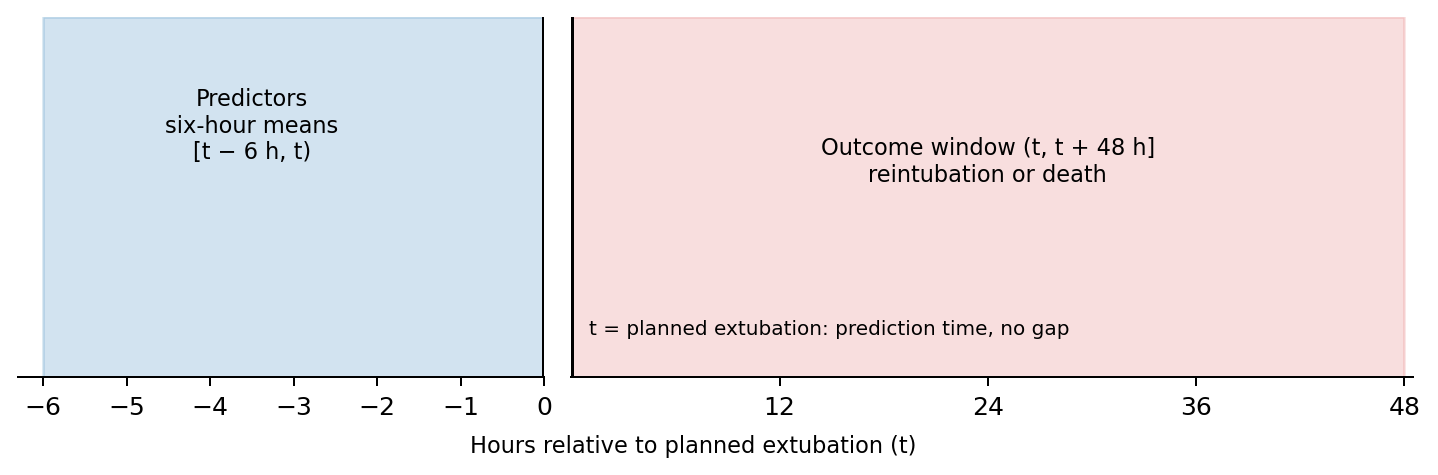

In [8]:
plot_study_timeline(SUITE_DIR)
display(Image(filename=str(SUITE_DIR / "study_timeline.png")))

## 5. Models, tuning and calibration

- **Models.** LR models linear effects on log odds; XGBoost also allows nonlinear effects and interactions. Each has a tuned and an untuned version.
- **Preprocessing.** Training-fold median imputation and categorical encoding are shared; both LR versions also use training-fold standardisation. No missingness indicators or engineered features are added.
- **Tuning comparison.** Tuned LR searches six C values; tuned XGBoost searches all 48 grid combinations. Inner-fold AUROC selects hyperparameters. Untuned LR fixes C = 1; untuned XGBoost fixes 250 trees, depth 3, learning rate 0.05, minimum child weight 1 and L2 regularisation 1. These are the existing project starting settings, not library defaults.
- **Class imbalance.** Both LR versions use balanced class weights; both XGBoost versions use the training-fold negative/positive ratio.
- **Calibration.** Weighting can distort risk estimates. Every version uses the same sigmoid calibration procedure with cross-validated predictions inside the training partition. Untuned versions skip only hyperparameter search.

In [9]:
class FoldBalancedXGB(ClassifierMixin, BaseEstimator):
    """XGBoost whose scale_pos_weight is recalculated from each training fold."""
    def __init__(self, n_estimators=250, max_depth=3, learning_rate=0.05,
                 min_child_weight=1, reg_lambda=1, subsample=0.8,
                 colsample_bytree=0.8, random_state=42, n_jobs=4):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.learning_rate = learning_rate
        self.min_child_weight = min_child_weight
        self.reg_lambda = reg_lambda
        self.subsample = subsample
        self.colsample_bytree = colsample_bytree
        self.random_state = random_state
        self.n_jobs = n_jobs

    def fit(self, X, y):
        counts = np.bincount(np.asarray(y, dtype=int), minlength=2)
        if min(counts) == 0:
            raise ValueError("XGBoost fit requires both classes.")
        # Negative/positive ratio of this training fold only.
        self.scale_pos_weight_ = float(counts[0] / counts[1])
        self.model_ = XGBClassifier(**self.get_params(), scale_pos_weight=self.scale_pos_weight_,
            objective="binary:logistic", eval_metric="logloss", tree_method="hist", device="cpu")
        self.model_.fit(X, y)
        self.classes_ = self.model_.classes_
        self.n_features_in_ = self.model_.n_features_in_
        return self

    def predict_proba(self, X):
        return self.model_.predict_proba(X)

    def predict(self, X):
        return self.model_.predict(X)


def model_pipeline(name, nums, cats, cfg):
    """Fold-wise preprocessing and model. Entirely missing training columns are kept (imputed as 0)."""
    numeric = [("impute", SimpleImputer(strategy="median", keep_empty_features=True))]
    if name == "logistic_regression":
        numeric.append(("scale", StandardScaler()))
    parts = [("numeric", Pipeline(numeric), nums)]
    if cats:
        categorical = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="unknown", keep_empty_features=True)),
            ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
        parts.append(("categorical", categorical, cats))
    prep = ColumnTransformer(parts, remainder="drop", sparse_threshold=0)
    if name == "logistic_regression":
        model = LogisticRegression(class_weight="balanced", solver="lbfgs", max_iter=cfg["lr_max_iter"], random_state=cfg["seed"])
    elif name == "xgboost":
        model = FoldBalancedXGB(random_state=cfg["seed"], n_jobs=cfg["xgb_threads"],
            subsample=cfg["xgb_subsample"], colsample_bytree=cfg["xgb_colsample_bytree"])
    else:
        raise ValueError(name)
    return Pipeline([("preprocess", prep), ("model", model)])


def fit_model(name, X, y, nums, cats, cfg, cv):
    """Fit fixed or searched hyperparameters, then apply the same training-only calibration."""
    family = name.removesuffix("_untuned")
    pipe = model_pipeline(family, nums, cats, cfg)
    if name in TUNED_MODELS:
        grid = ({"model__C": cfg["lr_c_values"]} if family == "logistic_regression"
                else {"model__" + key: values for key, values in cfg["xgb_param_grid"].items()})
        search = GridSearchCV(pipe, grid, cv=cv, scoring="roc_auc", refit=True,
            n_jobs=1, error_score="raise")
        search.fit(X, y)
        params = search.best_params_
        fitted = search.best_estimator_
    else:
        fixed = {"C": cfg["lr_fixed_c"]} if family == "logistic_regression" else cfg["xgb_fixed_params"]
        params = {"model__" + key: value for key, value in fixed.items()}
        fitted = pipe.set_params(**params)
    if cfg["calibrate"]:
        # Calibrator uses training-partition OOF scores; base model is then refitted on that partition.
        fitted = CalibratedClassifierCV(clone(fitted), method=cfg["calibration_method"],
            cv=cv, ensemble=False, n_jobs=1)
        fitted.fit(X, y)
    elif name not in TUNED_MODELS:
        fitted.fit(X, y)
    return fitted, params

## 6. Test-set metrics and figures

- **Comparators (proposal):** tuned LR (interpretable) and tuned XGBoost (black box); their untuned versions (exploratory); random guessing (baseline); RSBI (current practice), compared on the same RSBI-available patients. A six-hour RSBI summary is an adapted comparator, not the original bedside measurement.
- **Discrimination:** AUROC and average precision (AP) with patient-bootstrap 95% intervals. AP is judged against the prevalence (dotted reference line).
- **Probability accuracy and calibration:** Brier/scaled Brier, observed:expected ratio, calibration slope and calibration curves for the four models. A slope below 1 means predictions are too extreme on the evaluated population.
- **Classification:** sensitivity, specificity, PPV and NPV at each model's frozen development OOF threshold (maximum specificity at ≥80% sensitivity); RSBI uses its usual cut-off of 105. These are exploratory operating points.
- **Clinical utility:** decision curves on the same RSBI-available patients for the four models, RSBI ≥105, act-on-all and act-on-none.
- **Uncertainty:** 1,000 patient-bootstrap replicates; paired differences compare tuned XGBoost with tuned LR, and tuned with untuned versions. Intervals are conditional on the fitted models.
- **Additional analyses:** the full-cohort sensitivity analysis and AUROC for deaths and reintubations separately.

In [10]:
LABELS = {"logistic_regression": "LR (tuned)", "logistic_regression_untuned": "LR (untuned)",
    "xgboost": "XGBoost (tuned)", "xgboost_untuned": "XGBoost (untuned)",
    "random_guess": "Random guessing",
    "rsbi": "RSBI (continuous)", "rsbi_ge_105": "RSBI ≥ 105",
    "treat_all": "Act on all", "treat_none": "Act on none"}
COLOURS = {"logistic_regression": "tab:blue", "logistic_regression_untuned": "tab:blue",
    "xgboost": "tab:orange", "xgboost_untuned": "tab:orange",
    "random_guess": "#8c564b", "rsbi": "tab:green", "rsbi_ge_105": "tab:green",
    "treat_all": "grey", "treat_none": "black"}
LINESTYLES = {name: "--" if name.endswith("_untuned") or name.startswith("treat") else "-"
    for name in LABELS}
MARKERS = {name: "s" if name.endswith("_untuned") else "o" for name in LABELS}


def safe_ratio(a, b):
    return float(a / b) if b else np.nan


def calibration_summary(y, p):
    """Observed:expected ratio and calibration slope (outcome regressed on logit risk)."""
    p = np.clip(p, 1e-7, 1 - 1e-7)
    logit = np.log(p / (1 - p)).reshape(-1, 1)
    oe = safe_ratio(y.sum(), p.sum())
    if len(np.unique(y)) < 2 or np.std(logit) < 1e-12:
        return oe, np.nan
    # A very large C makes this effectively an unpenalised logistic regression.
    slope = LogisticRegression(C=1e10, max_iter=1000).fit(logit, y).coef_[0, 0]
    return oe, float(slope)


def metrics(y, score, threshold=0.5, probability=True, calibration=True):
    """Discrimination, threshold and (for probabilities) calibration metrics."""
    y, score = np.asarray(y, int), np.asarray(score, float)
    keep = np.isfinite(score)
    y, score = y[keep], score[keep]
    if not len(y):
        return {"n": 0}
    two = len(np.unique(y)) == 2
    prevalence = float(y.mean())
    tn, fp, fn, tp = confusion_matrix(y, score >= threshold, labels=[0, 1]).ravel()
    result = {"n": len(y), "events": int(y.sum()), "prevalence": prevalence,
        "auroc": roc_auc_score(y, score) if two else np.nan,
        "average_precision": average_precision_score(y, score) if two else np.nan,
        "threshold": float(threshold), "sensitivity": safe_ratio(tp, tp + fn),
        "specificity": safe_ratio(tn, tn + fp), "ppv": safe_ratio(tp, tp + fp),
        "npv": safe_ratio(tn, tn + fn), "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "brier": np.nan, "scaled_brier": np.nan, "log_loss": np.nan,
        "observed_expected_ratio": np.nan, "calibration_slope": np.nan}
    if probability:
        result["brier"] = brier_score_loss(y, score)
        result["scaled_brier"] = 1 - result["brier"] / (prevalence * (1 - prevalence)) if two else np.nan
        result["log_loss"] = log_loss(y, np.clip(score, 1e-7, 1 - 1e-7), labels=[0, 1])
        if calibration:
            result["observed_expected_ratio"], result["calibration_slope"] = calibration_summary(y, score)
    return result


def choose_threshold(y, score, sensitivity_target):
    """Maximise specificity at the target sensitivity using development OOF scores."""
    if not 0 < sensitivity_target <= 1:
        raise ValueError("sensitivity_target must be in (0,1].")
    fpr, tpr, thresholds = roc_curve(y, score, drop_intermediate=False)
    eligible = np.flatnonzero((tpr >= sensitivity_target) & np.isfinite(thresholds))
    # roc_curve thresholds descend: among tied FPR choose the highest threshold.
    best = eligible[np.argmin(fpr[eligible])]
    return float(thresholds[best])


def prediction_table(df, cfg, scores, rsbi_col, fold=None):
    """One row per patient: labels, evaluation-only descriptors and every model's score."""
    cols = [c for c in ["subject_id", "hadm_id", "stay_id", cfg["target"], *OUTCOME_COMPONENTS,
        "age", "admission_age", "gender", "sex"] if c in df]
    out = df[cols].copy().reset_index(drop=True)
    out = out.rename(columns={cfg["target"]: "y_true"})
    for name, values in scores.items():
        out[name] = values
    if rsbi_col:
        out["rsbi"] = df[rsbi_col].to_numpy()
    if fold is not None:
        out["outer_fold"] = fold
    return out


def comparison_tables(predictions, thresholds, calibration=True):
    """Metrics for every model on all patients and on the RSBI-available subset."""
    rows = []
    scopes = {"all_patients": np.ones(len(predictions), dtype=bool)}
    if "rsbi" in predictions:
        scopes["rsbi_available_same_patients"] = np.isfinite(predictions.rsbi)
    for scope, mask in scopes.items():
        p = predictions.loc[mask]
        for name in SCORE_MODELS:
            if name in p:
                # Calibration metrics apply to probability models only.
                rows.append({"scope": scope, "model": name, **metrics(p.y_true, p[name],
                    thresholds.get(name, 0.5), name in PROBABILITY_MODELS, calibration)})
        if scope == "rsbi_available_same_patients":
            rows.append({"scope": scope, "model": "rsbi", **metrics(p.y_true, p.rsbi, 105, False)})
    return pd.DataFrame(rows)


def bootstrap_intervals(p, thresholds, cfg):
    """Patient-bootstrap intervals and paired differences for the three planned model comparisons."""
    rng = np.random.default_rng(cfg["seed"] + 200)
    samples, differences = [], []
    for rep in range(cfg["bootstrap_replicates"]):
        sample = p.iloc[rng.integers(0, len(p), len(p))]
        table = comparison_tables(sample, thresholds, calibration=False)
        for _, row in table.iterrows():
            for metric in ["auroc", "average_precision", "sensitivity", "specificity", "ppv", "npv", "brier", "scaled_brier"]:
                samples.append({"replicate": rep, "scope": row.scope, "model": row.model,
                    "metric": metric, "value": row.get(metric, np.nan)})
        paired = table[table.scope.eq("all_patients")].set_index("model")
        for a, b in MODEL_PAIRS:
            for metric in ["auroc", "average_precision", "brier"]:
                differences.append({"model_a": a, "model_b": b, "metric": metric,
                    "value": paired.loc[a, metric] - paired.loc[b, metric]})

    def summarise(frame, groups):
        # Undefined single-class draws are omitted for that metric, with valid counts recorded.
        frame["value"] = frame["value"].where(np.isfinite(frame["value"]))
        return frame.groupby(groups).value.agg(valid_replicates="count",
            lower_95=lambda s: s.quantile(.025), upper_95=lambda s: s.quantile(.975)).reset_index()

    intervals = summarise(pd.DataFrame(samples), ["scope", "model", "metric"])
    paired_ci = summarise(pd.DataFrame(differences), ["model_a", "model_b", "metric"])
    point = comparison_tables(p, thresholds, calibration=False)
    point = point[point.scope.eq("all_patients")].set_index("model")
    paired_ci["n"], paired_ci["events"] = len(p), int(p.y_true.sum())
    paired_ci["a"] = [point.loc[r.model_a, r.metric] for r in paired_ci.itertuples()]
    paired_ci["b"] = [point.loc[r.model_b, r.metric] for r in paired_ci.itertuples()]
    paired_ci["a_minus_b"] = paired_ci.a - paired_ci.b
    return intervals, paired_ci


def paired_bootstrap(y, a, b, reps, seed):
    """Metrics of scores a and b and their difference (a − b) on the same resampled patients."""
    y, a, b = np.asarray(y, int), np.asarray(a, float), np.asarray(b, float)
    if not len(y):
        return []
    def values(i):
        two_classes = len(np.unique(y[i])) == 2
        return {"auroc": (roc_auc_score(y[i], a[i]), roc_auc_score(y[i], b[i])) if two_classes else (np.nan, np.nan),
                "average_precision": (average_precision_score(y[i], a[i]), average_precision_score(y[i], b[i])) if two_classes else (np.nan, np.nan),
                "brier": (brier_score_loss(y[i], a[i]), brier_score_loss(y[i], b[i]))}
    point = values(np.arange(len(y)))
    rng = np.random.default_rng(seed)
    draws = [values(rng.integers(0, len(y), len(y))) for _ in range(reps)]
    rows = []
    for metric, (va, vb) in point.items():
        diff = np.array([d[metric][0] - d[metric][1] for d in draws])
        diff = diff[np.isfinite(diff)]
        rows.append({"metric": metric, "a": va, "b": vb, "a_minus_b": va - vb,
            "lower_95": np.quantile(diff, .025) if len(diff) else np.nan,
            "upper_95": np.quantile(diff, .975) if len(diff) else np.nan, "valid_replicates": len(diff)})
    return rows


def rsbi_comparison(table, intervals):
    """Every comparator on identical RSBI-available patients, with AUROC/AP intervals."""
    scope = "rsbi_available_same_patients"
    columns = ["model", "n", "events", "auroc", "average_precision", "sensitivity", "specificity", "ppv", "npv"]
    matched = table.loc[table.scope.eq(scope) & table.model.isin(SCORE_MODELS + ["rsbi"])].reindex(columns=columns)
    for metric in ["auroc", "average_precision"]:
        ci = intervals.loc[intervals.scope.eq(scope) & intervals.metric.eq(metric), ["model", "lower_95", "upper_95"]]
        matched = matched.merge(ci.rename(columns={"lower_95": metric + "_lower_95", "upper_95": metric + "_upper_95"}),
            on="model", how="left", validate="one_to_one")
    return matched


def outcome_component_auroc(p):
    """AUROC for deaths and reintubations separately, each against patients with neither event.
    Models only: every model scores every patient, so all rows use the same patients."""
    rows = []
    negatives = p.y_true.eq(0)
    for component in OUTCOME_COMPONENTS:
        if component not in p:
            continue
        for name in MODEL_NAMES:
            keep = negatives | p[component].eq(1)
            y = p.loc[keep, component]
            rows.append({"component": component, "model": name, "events": int(y.sum()), "non_events": int((y == 0).sum()),
                "auroc": roc_auc_score(y, p.loc[keep, name]) if y.nunique() == 2 else np.nan})
    return pd.DataFrame(rows)



def net_benefit(y, flagged, threshold):
    """Net benefit of acting on flagged patients at one risk threshold (Vickers & Elkin 2006)."""
    n = len(y)
    tp = np.sum(flagged & (y == 1))
    fp = np.sum(flagged & (y == 0))
    return tp / n - fp / n * threshold / (1 - threshold)


def decision_curve(p, max_threshold, include_rsbi=False):
    """Net benefit of each model, act-on-all, act-on-none and (optionally) RSBI >= 105."""
    y = p.y_true.to_numpy()
    rows = []
    for t in np.round(np.arange(0.01, max_threshold + 1e-9, 0.005), 3):
        strategies = {name: p[name].to_numpy() >= t for name in MODEL_NAMES}
        if include_rsbi:
            strategies["rsbi_ge_105"] = p.rsbi.to_numpy() >= 105
        strategies["treat_all"] = np.ones(len(y), dtype=bool)
        rows += [{"threshold": t, "strategy": k, "net_benefit": net_benefit(y, v, t)} for k, v in strategies.items()]
        rows.append({"threshold": t, "strategy": "treat_none", "net_benefit": 0.0})
    return pd.DataFrame(rows)


def plot_model_comparison(primary, matched, path, title):
    """AUROC/AP with 95% CIs: all primary patients, then the same RSBI-available patients."""
    order = ["logistic_regression", "logistic_regression_untuned", "xgboost", "xgboost_untuned",
        "random_guess", "rsbi"]
    fig, axes = plt.subplots(2, 2, figsize=(12, 8.5))
    for row, (table, population) in enumerate([(primary, "All primary test patients"),
            (matched, "Same RSBI-available test patients")]):
        names = [name for name in order if name in set(table.model)] if "model" in table else []
        t = table.set_index("model").loc[names] if names else pd.DataFrame()
        counts = f"n={int(t.iloc[0]['n']):,}; events={int(t.iloc[0]['events']):,}" if names and t.iloc[0]["n"] > 0 else "unavailable"
        for col, (metric, label) in enumerate([("auroc", "AUROC"), ("average_precision", "Average precision")]):
            ax = axes[row, col]
            for y, name in enumerate(names):
                result = t.loc[name]
                value = result.get(metric, np.nan)
                if not np.isfinite(value):
                    ax.text(.5, y, "Not estimable", ha="center", va="center", fontsize=8, color="grey")
                    continue
                colour = COLOURS.get(name, "grey")
                lower, upper = result.get(metric + "_lower_95", np.nan), result.get(metric + "_upper_95", np.nan)
                if np.isfinite(lower) and np.isfinite(upper):
                    ax.hlines(y, lower, upper, color=colour, linewidth=1.7,
                        linestyle=LINESTYLES.get(name, "-"))
                ax.plot(value, y, marker=MARKERS.get(name, "o"), color=colour, markersize=6,
                    markerfacecolor="white" if name.endswith("_untuned") else colour, linestyle="none")
            reference = .5 if metric == "auroc" else (t.iloc[0]["events"] / t.iloc[0]["n"] if names and t.iloc[0]["n"] else np.nan)
            if np.isfinite(reference):
                ax.axvline(reference, color="grey", linestyle=":", linewidth=1)
            ax.set(xlim=(-.02, 1.02), ylim=(max(len(names), 1) - .5, -.5), xlabel=label,
                title=f"{population}\n({counts})" if col == 0 else label)
            ax.set_yticks(range(len(names)), [LABELS.get(name, name) for name in names] if col == 0 else [""] * len(names))
            ax.tick_params(axis="y", length=0, labelsize=9)
            ax.grid(axis="x", alpha=.18)
            ax.spines[["top", "right", "left"]].set_visible(False)
            if not names:
                ax.text(.5, .5, "RSBI comparison unavailable", transform=ax.transAxes, ha="center", va="center")
    fig.suptitle(title, fontsize=13)
    fig.text(.5, .025, "Bars: 95% patient-bootstrap CIs. Dotted references: AUROC 0.50; AP cohort prevalence.\n"
        "Untuned models are exploratory fixed-parameter comparators; RSBI discrimination uses its continuous value.",
        ha="center", fontsize=8)
    fig.tight_layout(rect=(0, .07, 1, .95), h_pad=2.5, w_pad=2)
    fig.savefig(path, dpi=180, bbox_inches="tight")
    plt.close(fig)


def plot_calibration_and_utility(p, max_threshold, folder, title):
    """All-patient probability calibration; matched-patient decision curves including RSBI."""
    if p.empty:
        raise ValueError("No patients available for calibration or decision-curve evaluation.")
    folder = Path(folder)
    matched = p.loc[np.isfinite(p.rsbi)] if "rsbi" in p else p.iloc[:0]
    use_rsbi = matched.y_true.nunique() == 2
    if not use_rsbi:
        warnings.warn("RSBI comparison unavailable (no RSBI or one outcome class); showing all-patient decision curves.")
    elif min(int(matched.y_true.sum()), int((matched.y_true == 0).sum())) < 20:
        warnings.warn("RSBI decision curve has fewer than 20 events or non-events; interpret cautiously.")
    dca_patients = matched if use_rsbi else p
    curve = decision_curve(dca_patients, max_threshold, include_rsbi=use_rsbi)
    curve.to_csv(folder / "FINAL_decision_curve.csv", index=False)

    fig, (cal, dca) = plt.subplots(1, 2, figsize=(12.5, 6))
    # Quantile bins target about ten events each.
    n_bins = int(np.clip(p.y_true.sum() // 10, 3, 10))
    limit = .1
    for model in PROBABILITY_MODELS:
        if model not in p:
            continue
        observed, predicted = calibration_curve(p.y_true, p[model], n_bins=n_bins, strategy="quantile")
        colour = COLOURS.get(model, "grey")
        cal.plot(predicted, observed, marker=MARKERS.get(model, "o"), color=colour,
            markerfacecolor="white" if model.endswith("_untuned") else colour,
            linestyle=LINESTYLES.get(model, "-"), markersize=4, label=LABELS.get(model, model))
        limit = max(limit, 1.1 * max(predicted.max(), observed.max()))
    limit = min(limit, 1)
    cal.plot([0, limit], [0, limit], color="black", linestyle=":", alpha=.65, label="Ideal calibration")
    cal.set(xlim=(0, limit), ylim=(0, limit), xlabel="Mean predicted risk", ylabel="Observed event rate",
        title=f"Calibration: all primary test patients\n(n={len(p):,}; events={int(p.y_true.sum()):,})")
    for strategy, group in curve.groupby("strategy", sort=False):
        dca.plot(group.threshold, group.net_benefit, label=LABELS.get(strategy, strategy),
            color=COLOURS.get(strategy, "grey"), linestyle=LINESTYLES.get(strategy, "-"), linewidth=1.6)
    # Keep the full net-benefit range so poor comparators remain visible.
    dca.margins(y=.08)
    population = "same RSBI-available test patients" if use_rsbi else "all primary test patients"
    dca.set(xlabel="Risk threshold for acting on an alert", ylabel="Net benefit",
        title=f"Decision curve: {population}\n(n={len(dca_patients):,}; events={int(dca_patients.y_true.sum()):,})")
    for ax in (cal, dca):
        ax.grid(alpha=.15)
        ax.spines[["top", "right"]].set_visible(False)
    cal.legend(fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.19), ncol=2, frameon=False)
    dca.legend(fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.19), ncol=3, frameon=False,
        columnspacing=.9, handlelength=2)
    fig.suptitle(title, fontsize=13)
    fig.text(.5, .015, "Untuned models are exploratory. RSBI is not a calibrated probability; "
        "RSBI ≥ 105 is a fixed decision rule.", ha="center", fontsize=8)
    fig.subplots_adjust(left=.07, right=.985, top=.84, bottom=.31, wspace=.27)
    path = folder / "FINAL_calibration_decision_curve.png"
    fig.savefig(path, dpi=180, bbox_inches="tight")
    plt.close(fig)
    return path


## 7. Model development (nested cross-validation)

The same five outer folds evaluate tuned and untuned LR/XGBoost. Three inner folds select hyperparameters for tuned versions and provide calibration predictions for all versions. Outer validation patients never enter their model's fitting, tuning or calibration.

The preferred model remains the tuned family with higher mean outer-fold AUROC. Each of the four versions receives its own threshold from development OOF predictions. All four are refitted on development patients; untuned settings remain fixed. The development table records fold performance, thresholds and final hyperparameters.

In [11]:
def run_development(config):
    """Nested CV for model selection and thresholds, then final refit on all development patients."""
    cfg = validate_config(config)
    out = Path(cfg["output_dir"])
    df, nums, cats, rsbi_col, hashes = load_cohort(cfg)
    locked = (out / "final_test_started.json").exists() or (Path(cfg["suite_output_dir"]) / "final_suite_started.json").exists()
    cache_files = ["frozen_analysis.json", "trained_models.joblib", "development_oof_predictions.csv", "environment_versions.json"]
    cached = all((out / name).exists() for name in cache_files)
    reuse = False
    if cached or locked:
        frozen = json.loads((out / "frozen_analysis.json").read_text())
        reuse = (cached and cfg == frozen["config"] and hashes == frozen["source_hashes"]
            and json.loads((out / "environment_versions.json").read_text()) == environment_versions())
        if locked and not reuse:
            raise RuntimeError("Final test already opened and settings/data/environment changed. Restore the frozen analysis.")
    if reuse:
        bundle = joblib.load(out / "trained_models.joblib")
        dev = df.set_index("subject_id", drop=False).loc[bundle["development_ids"]].reset_index(drop=True)
        print("Reusing completed development: settings, source data and environment are unchanged.")
        return {"bundle": bundle, "data": df, "development": dev, "output_dir": out,
            "oof": pd.read_csv(out / "development_oof_predictions.csv", dtype={"subject_id": "string"})}
    manifest, dev_idx, test_idx, split_note = make_split(df, cfg)
    holdout = holdout_status(df, test_idx, cfg)
    out.mkdir(parents=True, exist_ok=True)
    dev = df.iloc[dev_idx].reset_index(drop=True)
    followup = followup_summary(dev, cfg)
    if followup["negative_labels_without_complete_observation"]:
        warnings.warn(f"{cfg['analysis']}: {followup['negative_labels_without_complete_observation']} development negatives lack complete 48-hour observation. Supplied labels are retained; describe this limitation.")
    X, y = dev[nums + cats], dev[cfg["target"]].to_numpy()

    # The same outer validation patients are scored by each variant fitted without them.
    outer = checked_cv(y, cfg["outer_folds"], cfg["seed"])
    scores = {name: np.full(len(dev), np.nan) for name in MODEL_NAMES}
    folds = np.full(len(dev), -1, dtype=int)
    fold_auroc = {name: [] for name in MODEL_NAMES}
    fold_parameters = []
    for fold, (train, valid) in enumerate(outer):
        inner = checked_cv(y[train], cfg["inner_folds"], cfg["seed"] + fold + 1)
        folds[valid] = fold
        for name in MODEL_NAMES:
            print(f"Outer fold {fold + 1}/{len(outer)}: {name}", flush=True)
            fitted, params = fit_model(name, X.iloc[train], y[train], nums, cats, cfg, inner)
            scores[name][valid] = fitted.predict_proba(X.iloc[valid])[:, 1]
            fold_auroc[name].append(float(roc_auc_score(y[valid], scores[name][valid])))
            fold_parameters.append({"outer_fold": fold, "model": name, "parameters": params})
    assert all(np.isfinite(s).all() for s in scores.values()) and (folds >= 0).all()
    oof = prediction_table(dev, cfg, scores, rsbi_col, folds)
    oof.to_csv(out / "development_oof_predictions.csv", index=False)

    # Model selection and thresholds from development OOF predictions only.
    mean_auroc = {name: float(np.mean(v)) for name, v in fold_auroc.items()}
    winner = max(TUNED_MODELS, key=mean_auroc.get)  # untuned variants are comparison-only
    thresholds = {name: choose_threshold(y, scores[name], cfg["sensitivity_target"]) for name in MODEL_NAMES}
    thresholds["random_guess"] = 0.5
    if cfg["analysis"] == "filtered_six_hour":
        # Same predictors in every analysis, so one missingness table (primary cohort) is enough.
        dev[nums + cats].isna().mean().rename("missing_fraction_development").sort_values(ascending=False).to_csv(
            out / "development_feature_missingness.csv")

    # Final models: tune or keep fixed settings, then calibrate/refit on development patients.
    final_models, final_params = {}, {}
    final_cv = checked_cv(y, cfg["inner_folds"], cfg["seed"] + 100)
    for name in MODEL_NAMES:
        print(f"Refitting {name} on development patients only", flush=True)
        final_models[name], final_params[name] = fit_model(name, X, y, nums, cats, cfg, final_cv)
    write_json(out / "environment_versions.json", environment_versions())
    frozen = {"config": cfg, "source_hashes": hashes, "split": split_note,
        "selected_features": nums + cats, "rsbi_column": rsbi_col,
        "partition_counts": manifest.partition.value_counts().to_dict(), "holdout": holdout,
        "thresholds": thresholds, "threshold_rule": "maximum specificity at development OOF sensitivity >= configured target",
        "selected_primary_model": winner, "selection_rule": "highest mean outer-fold AUROC among tuned models",
        "outer_fold_auroc": fold_auroc, "mean_outer_fold_auroc": mean_auroc,
        "outer_fold_parameters": fold_parameters, "final_parameters": final_params,
        "development_n": len(dev), "development_events": int(y.sum()), "development_followup": followup,
        "test_outcomes_used_for_training_or_selection": False}
    write_json(out / "frozen_analysis.json", frozen)
    bundle = {"models": final_models, "frozen": frozen,
        "development_ids": dev.subject_id.tolist(), "test_ids": df.iloc[test_idx].subject_id.tolist()}
    joblib.dump(bundle, out / "trained_models.joblib")
    print(f"Development complete. Selected model: {winner}. Models frozen.")
    return {"bundle": bundle, "data": df, "development": dev, "oof": oof, "output_dir": out}


def model_selection_summary(runs):
    """Development comparison and reproducibility record for all four variants."""
    rows = []
    for analysis, run in runs.items():
        frozen = run["bundle"]["frozen"]
        for name in MODEL_NAMES:
            auroc = frozen["outer_fold_auroc"][name]
            rows.append({"analysis": analysis, "model": name, "tuned": name in TUNED_MODELS,
                "development_patients": frozen["development_n"], "development_events": frozen["development_events"],
                "outer_fold_auroc_mean": np.mean(auroc), "outer_fold_auroc_sd": np.std(auroc, ddof=1),
                "selected": name == frozen["selected_primary_model"], "threshold": frozen["thresholds"][name],
                "final_hyperparameters": {k.removeprefix("model__"): v for k, v in frozen["final_parameters"][name].items()}})
    return pd.DataFrame(rows)

In [12]:
guard_final_suite(RUN_CONFIGS)
runs = {}
for analysis, cfg in RUN_CONFIGS.items():
    print(f"\n{analysis}", flush=True)
    runs[analysis] = run_development(cfg)
primary_dir = runs["filtered_six_hour"]["output_dir"]

# Development comparison: fold AUROC, selected tuned family, thresholds and fitted settings.
MODEL_SELECTION = model_selection_summary(runs)
MODEL_SELECTION.to_csv(SUITE_DIR / "model_selection.csv", index=False)
display(MODEL_SELECTION.round(3))


filtered_six_hour
Outer fold 1/5: logistic_regression


/var/folders/0y/926bml0x27j90kg_6jr1s2h00000gn/T/ipykernel_43558/2875927676.py:28: UserWarning: filtered_six_hour: 496 development negatives lack complete 48-hour observation. Supplied labels are retained; describe this limitation.
  warnings.warn(f"{cfg['analysis']}: {followup['negative_labels_without_complete_observation']} development negatives lack complete 48-hour observation. Supplied labels are retained; describe this limitation.")


Outer fold 1/5: logistic_regression_untuned
Outer fold 1/5: xgboost
Outer fold 1/5: xgboost_untuned
Outer fold 2/5: logistic_regression
Outer fold 2/5: logistic_regression_untuned
Outer fold 2/5: xgboost
Outer fold 2/5: xgboost_untuned
Outer fold 3/5: logistic_regression
Outer fold 3/5: logistic_regression_untuned
Outer fold 3/5: xgboost
Outer fold 3/5: xgboost_untuned
Outer fold 4/5: logistic_regression
Outer fold 4/5: logistic_regression_untuned
Outer fold 4/5: xgboost
Outer fold 4/5: xgboost_untuned
Outer fold 5/5: logistic_regression
Outer fold 5/5: logistic_regression_untuned
Outer fold 5/5: xgboost
Outer fold 5/5: xgboost_untuned
Refitting logistic_regression on development patients only
Refitting logistic_regression_untuned on development patients only
Refitting xgboost on development patients only
Refitting xgboost_untuned on development patients only
Development complete. Selected model: xgboost. Models frozen.

full_six_hour
Outer fold 1/5: logistic_regression


/var/folders/0y/926bml0x27j90kg_6jr1s2h00000gn/T/ipykernel_43558/2875927676.py:28: UserWarning: full_six_hour: 672 development negatives lack complete 48-hour observation. Supplied labels are retained; describe this limitation.
  warnings.warn(f"{cfg['analysis']}: {followup['negative_labels_without_complete_observation']} development negatives lack complete 48-hour observation. Supplied labels are retained; describe this limitation.")


Outer fold 1/5: logistic_regression_untuned
Outer fold 1/5: xgboost
Outer fold 1/5: xgboost_untuned
Outer fold 2/5: logistic_regression
Outer fold 2/5: logistic_regression_untuned
Outer fold 2/5: xgboost
Outer fold 2/5: xgboost_untuned
Outer fold 3/5: logistic_regression
Outer fold 3/5: logistic_regression_untuned
Outer fold 3/5: xgboost
Outer fold 3/5: xgboost_untuned
Outer fold 4/5: logistic_regression
Outer fold 4/5: logistic_regression_untuned
Outer fold 4/5: xgboost
Outer fold 4/5: xgboost_untuned
Outer fold 5/5: logistic_regression
Outer fold 5/5: logistic_regression_untuned
Outer fold 5/5: xgboost
Outer fold 5/5: xgboost_untuned
Refitting logistic_regression on development patients only
Refitting logistic_regression_untuned on development patients only
Refitting xgboost on development patients only
Refitting xgboost_untuned on development patients only
Development complete. Selected model: xgboost. Models frozen.


,analysis,model,tuned,development_patients,development_events,outer_fold_auroc_mean,outer_fold_auroc_sd,selected,threshold,final_hyperparameters
0,filtered_six_hour,logistic_regression,True,15493,1503,0.812,0.013,False,0.083,{'C': 0.1}
1,filtered_six_hour,logistic_regression_untuned,False,15493,1503,0.812,0.012,False,0.084,{'C': 1.0}
2,filtered_six_hour,xgboost,True,15493,1503,0.827,0.011,True,0.083,"{'learning_rate': 0.03, 'max_depth': 3, 'min_c..."
3,filtered_six_hour,xgboost_untuned,False,15493,1503,0.825,0.011,False,0.081,"{'n_estimators': 250, 'max_depth': 3, 'learnin..."
4,full_six_hour,logistic_regression,True,17034,2059,0.821,0.015,False,0.103,{'C': 0.1}
5,full_six_hour,logistic_regression_untuned,False,17034,2059,0.821,0.015,False,0.103,{'C': 1.0}
6,full_six_hour,xgboost,True,17034,2059,0.849,0.011,True,0.100,"{'learning_rate': 0.03, 'max_depth': 4, 'min_c..."
7,full_six_hour,xgboost_untuned,False,17034,2059,0.846,0.010,False,0.099,"{'n_estimators': 250, 'max_depth': 3, 'learnin..."


## 8. Development interpretation

Primary-cohort development patients only, using the two tuned models. Show the ten largest numeric LR coefficients (log odds per SD after training-median imputation) and the ten leading XGBoost variables by mean absolute TreeSHAP. Both describe base models before calibration; SHAP sums encoded columns by source variable. Full tables are saved. These are predictive associations, not causal effects. Check feature missingness before interpreting nearly all-missing predictors.

In [13]:
def base_pipeline(model):
    """Uncalibrated tuned pipeline inside a calibrated model."""
    return model.calibrated_classifiers_[0].estimator if isinstance(model, CalibratedClassifierCV) else model


def transformed_variable(name, categorical):
    """Map a transformed column (numeric__RSBI_mean_6h, categorical__gender_M) to its source variable."""
    prefix, _, column = name.partition("__")
    if prefix == "categorical":
        return next((c for c in categorical if column.startswith(c + "_")), column)
    return feature_family(column)


def export_interpretation(run):
    """Coefficient and SHAP tables plus one figure for the primary analysis."""
    bundle, dev, out = run["bundle"], run["development"], run["output_dir"]
    cfg = bundle["frozen"]["config"]
    features = bundle["frozen"]["selected_features"]
    categorical = [c for c in features if c in cfg["categorical_columns"]]

    lr = base_pipeline(bundle["models"]["logistic_regression"])
    names = lr.named_steps["preprocess"].get_feature_names_out()
    coefficients = pd.DataFrame({"feature": names, "variable": [transformed_variable(n, categorical) for n in names],
        "coefficient": lr.named_steps["model"].coef_[0]})
    coefficients["abs_coefficient"] = coefficients.coefficient.abs()
    coefficients = coefficients.sort_values("abs_coefficient", ascending=False)
    coefficients.to_csv(out / "logistic_base_coefficients.csv", index=False)

    # Native TreeSHAP contributions sum to the base model's log odds.
    xgb = base_pipeline(bundle["models"]["xgboost"])
    transformed = xgb.named_steps["preprocess"].transform(dev[features])
    booster = xgb.named_steps["model"].model_.get_booster()
    contrib = booster.predict(DMatrix(transformed), pred_contribs=True)
    margin = booster.predict(DMatrix(transformed), output_margin=True)
    np.testing.assert_allclose(contrib.sum(axis=1), margin, atol=1e-4, rtol=1e-4)
    columns = xgb.named_steps["preprocess"].get_feature_names_out()
    shap_frame = pd.DataFrame(contrib[:, :-1], columns=columns)
    # Combine encoded columns belonging to the same source variable.
    variables = np.array([transformed_variable(c, categorical) for c in columns])
    variable_shap = shap_frame.T.groupby(variables).sum().T
    importance = (variable_shap.abs().mean().sort_values(ascending=False)
        .rename("mean_abs_shap_log_odds").rename_axis("variable").reset_index())
    importance.to_csv(out / "xgboost_base_treeshap_by_variable.csv", index=False)

    # Figure: ten largest numeric LR coefficients and ten leading XGBoost variables.
    numeric_coefficients = coefficients[coefficients.feature.str.startswith("numeric__")].head(10).iloc[::-1]
    top = importance.head(10).iloc[::-1]
    fig, (lr_ax, xgb_ax) = plt.subplots(1, 2, figsize=(12, 4.8))
    lr_ax.barh(numeric_coefficients.variable, numeric_coefficients.coefficient, color="tab:blue")
    lr_ax.axvline(0, color="k", lw=.7)
    lr_ax.set(xlabel="Log odds per SD (base model)", title="A  Tuned logistic regression")
    xgb_ax.barh(top.variable, top.mean_abs_shap_log_odds, color="tab:orange")
    xgb_ax.set(xlabel="Mean |TreeSHAP| (base-model log odds)", title="B  Tuned XGBoost")
    fig.tight_layout()
    fig.savefig(out / "interpretation_lr_shap.png", dpi=180, bbox_inches="tight")
    plt.close(fig)
    return coefficients, importance

,feature,variable,coefficient,abs_coefficient
24,categorical__icu_type_at_admission_Cardiac Vas...,icu_type_at_admission,-1.370,1.370
32,categorical__icu_type_at_admission_Neuro Surgi...,icu_type_at_admission,0.956,0.956
9,numeric__tidal_volume_spontaneous_mean_6h,tidal_volume_spontaneous,-0.724,0.724
1,numeric__icu_hours_before_extubation,icu_hours_before_extubation,0.433,0.433
12,numeric__peep_mean_6h,peep,0.354,0.354
0,numeric__admission_age,admission_age,0.347,0.347
29,categorical__icu_type_at_admission_Medical/Sur...,icu_type_at_admission,-0.254,0.254
5,numeric__resp_rate_mean_6h,resp_rate,0.251,0.251
33,categorical__icu_type_at_admission_PACU,icu_type_at_admission,0.227,0.227
35,categorical__icu_type_at_admission_Trauma SICU...,icu_type_at_admission,0.202,0.202


,variable,mean_abs_shap_log_odds
0,icu_hours_before_extubation,0.7562
1,icu_type_at_admission,0.4934
2,admission_age,0.2530
3,peep,0.1887
4,resp_rate,0.1829
5,heart_rate,0.1780
6,minute_volume,0.1167
7,spo2,0.0990
8,ph,0.0960
9,temperature,0.0877


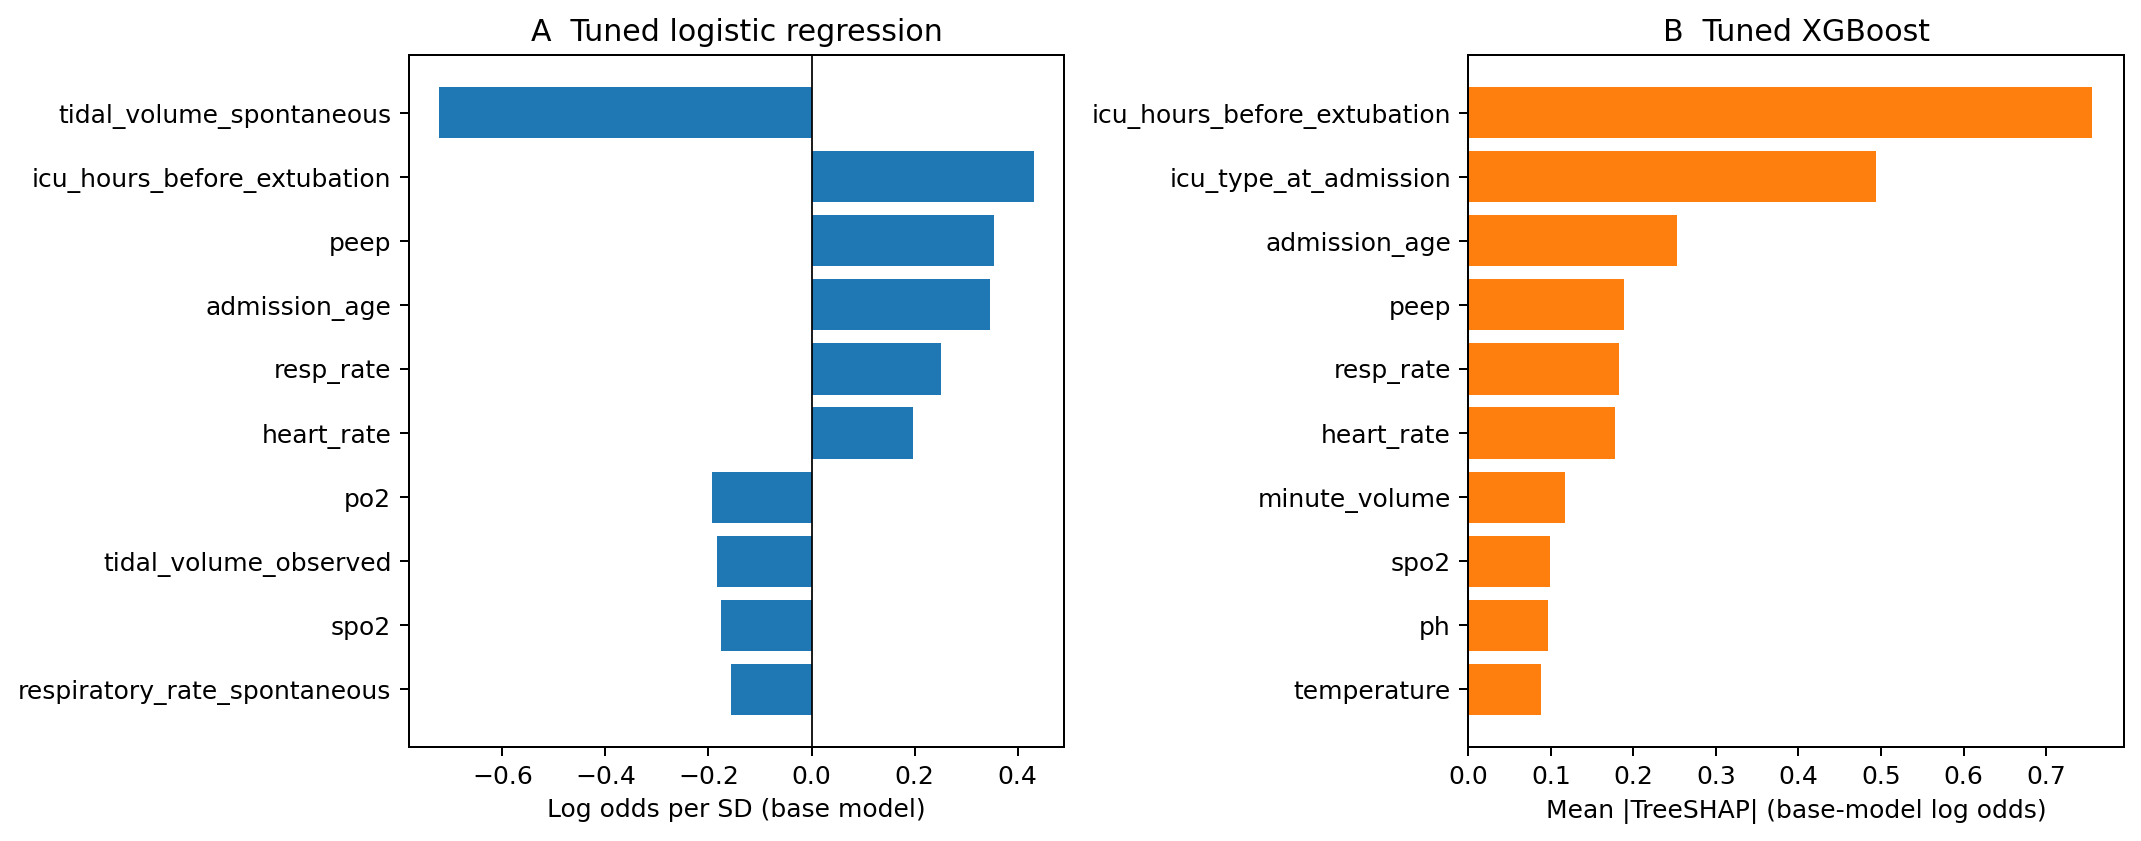

Most-missing predictors (development patients): read coefficients for these with caution


,Unnamed: 0,missing_fraction_development
0,bicarbonate_mean_6h,0.999
1,pao2fio2ratio_mean_6h,0.893
2,fio2_mean_6h,0.893
3,lactate_mean_6h,0.649
4,po2_mean_6h,0.376
5,pco2_mean_6h,0.376
6,ph_mean_6h,0.373
7,RSBI_mean_6h,0.215


In [14]:
# Interpretation uses the primary cohort's development patients only.
lr_coefficients, xgb_importance = export_interpretation(runs["filtered_six_hour"])
display(lr_coefficients.head(10).round(3))
display(xgb_importance.head(10).round(4))
display(Image(filename=str(primary_dir / "interpretation_lr_shap.png")))
print("Most-missing predictors (development patients): read coefficients for these with caution")
display(pd.read_csv(primary_dir / "development_feature_missingness.csv").head(8).round(3))

## 9. Temporal test evaluation

This revised evaluation freezes all four variants for both cohorts before scoring. Untuned comparisons were added after an earlier test evaluation and are exploratory. Identical reruns reload the saved results; changes to this frozen revision are rejected.

Printed and saved:
1. Table 1 and test metrics for both six-hour cohorts: the four model versions and random guessing.
2. One comparison figure: AUROC and AP with 95% CIs on all primary-test patients and on the same RSBI-available patients. The latter includes continuous RSBI.
3. One calibration/decision-curve figure: calibration of the four models; decision curves with RSBI ≥105.
4. Paired tuned XGBoost − tuned LR and tuned − untuned differences; a matched RSBI comparison table.
5. The full-cohort six-hour sensitivity analysis, with paired differences on retained patients and patients excluded by the missingness filter.
6. AUROC for deaths and reintubations separately (exploratory).

In [15]:
def final_evaluation(run):
    """Score one frozen analysis on its temporal test set and save its results."""
    bundle, df, out = run["bundle"], run["data"], run["output_dir"]
    frozen = bundle["frozen"]
    cfg = frozen["config"]
    marker = out / "final_test_started.json"
    signature = hashlib.sha256(json.dumps(frozen, sort_keys=True).encode()).hexdigest()
    model_hash = file_hash(out / "trained_models.joblib")
    if marker.exists():
        prior = json.loads(marker.read_text())
        if prior.get("analysis_signature") != signature or prior.get("model_sha256") != model_hash:
            raise RuntimeError("Models or settings changed after final evaluation started.")
        if prior["status"] == "completed":
            print("Loading saved final-test results.")
            return
        print("Resuming final evaluation with the saved models.")
    test = df.set_index("subject_id", drop=False).loc[bundle["test_ids"]].reset_index(drop=True)
    warn_small_holdout(frozen["holdout"], cfg)
    # Save the marker before evaluation so interrupted runs can resume.
    marker_info = {"analysis_signature": signature, "model_sha256": model_hash, "holdout": frozen["holdout"]}
    write_json(marker, {**marker_info, "status": "started"})
    X = test[frozen["selected_features"]]
    scores = {n: m.predict_proba(X)[:, 1] for n, m in bundle["models"].items()}
    scores["random_guess"] = np.random.default_rng(cfg["seed"] + 300).uniform(size=len(test))
    p = prediction_table(test, cfg, scores, frozen["rsbi_column"])
    p.to_csv(out / "FINAL_test_predictions.csv", index=False)
    table = comparison_tables(p, frozen["thresholds"])
    table.to_csv(out / "FINAL_test_metrics.csv", index=False)
    ci, differences = bootstrap_intervals(p, frozen["thresholds"], cfg)
    ci.to_csv(out / "FINAL_test_patient_bootstrap_CI.csv", index=False)
    if cfg["analysis"] == "filtered_six_hour":
        # Paired model differences and outcome components for the primary analysis only.
        differences.to_csv(out / "FINAL_paired_model_differences_CI.csv", index=False)
        outcome_component_auroc(p).to_csv(out / "FINAL_outcome_component_auroc.csv", index=False)
    write_json(marker, {**marker_info, "status": "completed"})


def evaluate_suite(runs, configs):
    """Lock every analysis, then score every test set and combine the headline metrics."""
    guard_final_suite(configs)
    marker = SUITE_DIR / "final_suite_started.json"
    if not marker.exists():
        for name, cfg in configs.items():
            frozen = runs[name]["bundle"]["frozen"]
            if cfg != frozen["config"] or load_cohort(cfg)[-1] != frozen["source_hashes"]:
                raise RuntimeError("Data or settings changed since development. Refit all analyses before opening the test set.")
        write_json(marker, {"status": "started", "primary_analysis": "filtered_six_hour", "plan": suite_plan(configs),
            "model_hashes": {name: file_hash(run["output_dir"] / "trained_models.joblib") for name, run in runs.items()},
            "analysis_hashes": {name: file_hash(run["output_dir"] / "frozen_analysis.json") for name, run in runs.items()}})
    # The complete suite is locked BEFORE any overlapping test set is scored.
    rows = []
    for name, run in runs.items():
        cfg = configs[name]
        print("Test evaluation:", name)
        final_evaluation(run)
        table = pd.read_csv(run["output_dir"] / "FINAL_test_metrics.csv")
        table = table[table.scope.eq("all_patients") & table.model.isin(SCORE_MODELS)].drop(columns="scope")
        ci = pd.read_csv(run["output_dir"] / "FINAL_test_patient_bootstrap_CI.csv")
        ci = ci[ci.scope.eq("all_patients") & ci.metric.isin(["auroc", "average_precision"])]
        wide = ci.pivot(index="model", columns="metric", values=["lower_95", "upper_95"])
        wide.columns = [f"{metric}_{bound}" for bound, metric in wide.columns]
        rows.append(table.merge(wide, left_on="model", right_index=True, how="left").assign(
            analysis=name, analysis_note=cfg["analysis_note"]))
    result = pd.concat(rows, ignore_index=True)
    result.to_csv(SUITE_DIR / "FINAL_analysis_comparison.csv", index=False)
    saved = json.loads(marker.read_text())
    write_json(marker, {**saved, "status": "completed"})
    return result


def test_predictions(run):
    """Saved test-set predictions of one analysis, indexed by patient."""
    return pd.read_csv(run["output_dir"] / "FINAL_test_predictions.csv", dtype={"subject_id": "string"}).set_index("subject_id")


def test_sensitivity_analyses(runs):
    """Missingness-filter sensitivity analysis on the test set; each row is a paired difference A − B."""
    primary = runs["filtered_six_hour"]
    cfg = primary["bundle"]["frozen"]["config"]
    reps, seed = cfg["bootstrap_replicates"], cfg["seed"] + 400
    main = test_predictions(primary)
    full = test_predictions(runs["full_six_hour"])
    removed = full.index.difference(main.index)  # test patients excluded by the missingness filter
    removed_X = runs["full_six_hour"]["data"].set_index("subject_id").loc[removed, primary["bundle"]["frozen"]["selected_features"]]
    comparisons = []
    for name in MODEL_NAMES:
        comparisons.append(("A full-cohort vs B filtered-cohort training (filtered-cohort patients)",
            name, main.y_true, full.loc[main.index, name], main[name]))
        if len(removed):
            filtered_scores = primary["bundle"]["models"][name].predict_proba(removed_X)[:, 1]
            comparisons.append(("A full-cohort vs B filtered-cohort training (patients removed by filter)",
                name, full.loc[removed, "y_true"], full.loc[removed, name], filtered_scores))
    rows = []
    for i, (label, name, y, a, b) in enumerate(comparisons):
        for r in paired_bootstrap(y, a, b, reps, seed + i):
            rows.append({"comparison": label, "model": name, "patients": len(y), "events": int(np.sum(y)), **r})
    table = pd.DataFrame(rows).rename(columns={"a": "A", "b": "B", "a_minus_b": "A_minus_B"})
    table.to_csv(SUITE_DIR / "FINAL_sensitivity_analyses.csv", index=False)
    return table

Test evaluation: filtered_six_hour
Test evaluation: full_six_hour
Table 1: primary cohort (development and temporal test) and patients removed by the missingness filter


,Characteristic,Development,Temporal test,Removed by missingness filter (all years),Full eligible cohort (all years)
0,"Patients, n",15493,897,1875,19021
1,"Age, median [IQR]",66 [55–76],65 [54–74],64 [51–78],66 [55–76]
2,"Female, n (%)",5899 (38.1%),319 (35.6%),827 (44.1%),7364 (38.7%)
3,"ICU hours before extubation, median [IQR]",22.3 [10.6–65.6],40.6 [15.8–101.6],33.8 [14.6–94.3],23.9 [11.2–70.6]
4,"Hospital hours before extubation, median [IQR]",49.1 [22.4–126.0],69.8 [34.0–164.5],46.6 [18.4–140.1],50.6 [22.6–131.9]
5,ICU type: Cardiac Vascular Intensive Care Unit...,6144 (39.7%),328 (36.6%),69 (3.7%),6746 (35.5%)
6,"ICU type: Medical Intensive Care Unit (MICU), ...",2404 (15.5%),124 (13.8%),513 (27.4%),3200 (16.8%)
7,"ICU type: Surgical Intensive Care Unit (SICU),...",2202 (14.2%),76 (8.5%),324 (17.3%),2701 (14.2%)
8,"ICU type: Trauma SICU (TSICU), n (%)",2025 (13.1%),113 (12.6%),341 (18.2%),2546 (13.4%)
9,ICU type: Medical/Surgical Intensive Care Unit...,1424 (9.2%),63 (7.0%),274 (14.6%),1854 (9.7%)


Table 2: temporal test performance (primary and full-cohort six-hour sensitivity; untuned comparisons exploratory)


,analysis,model,n,events,prevalence,auroc,auroc_lower_95,auroc_upper_95,average_precision,average_precision_lower_95,average_precision_upper_95,brier,scaled_brier,calibration_slope,observed_expected_ratio,threshold,sensitivity,specificity,ppv,npv
0,filtered_six_hour,logistic_regression,897,106,0.118,0.835,0.794,0.873,0.469,0.379,0.573,0.081,0.227,1.010,0.915,0.083,0.906,0.598,0.232,0.979
1,filtered_six_hour,logistic_regression_untuned,897,106,0.118,0.834,0.792,0.871,0.465,0.375,0.568,0.081,0.222,0.993,0.898,0.084,0.906,0.602,0.234,0.979
2,filtered_six_hour,xgboost,897,106,0.118,0.835,0.795,0.874,0.507,0.414,0.606,0.080,0.228,1.166,0.907,0.083,0.868,0.571,0.213,0.970
3,filtered_six_hour,xgboost_untuned,897,106,0.118,0.831,0.790,0.868,0.499,0.406,0.595,0.081,0.219,1.166,0.911,0.081,0.868,0.560,0.209,0.969
4,filtered_six_hour,random_guess,897,106,0.118,0.501,0.444,0.555,0.115,0.093,0.145,NaN,NaN,NaN,NaN,0.500,0.538,0.479,0.122,0.886
5,full_six_hour,logistic_regression,1093,163,0.149,0.825,0.790,0.859,0.468,0.399,0.553,0.101,0.204,0.844,0.893,0.103,0.877,0.596,0.276,0.965
6,full_six_hour,logistic_regression_untuned,1093,163,0.149,0.822,0.787,0.857,0.464,0.395,0.549,0.102,0.200,0.846,0.889,0.103,0.871,0.590,0.272,0.963
7,full_six_hour,xgboost,1093,163,0.149,0.825,0.791,0.858,0.494,0.419,0.574,0.102,0.193,0.925,0.805,0.100,0.871,0.566,0.260,0.962
8,full_six_hour,xgboost_untuned,1093,163,0.149,0.827,0.794,0.860,0.501,0.426,0.579,0.102,0.200,0.957,0.821,0.099,0.877,0.562,0.260,0.963
9,full_six_hour,random_guess,1093,163,0.149,0.512,0.465,0.558,0.154,0.129,0.188,NaN,NaN,NaN,NaN,0.500,0.503,0.484,0.146,0.847


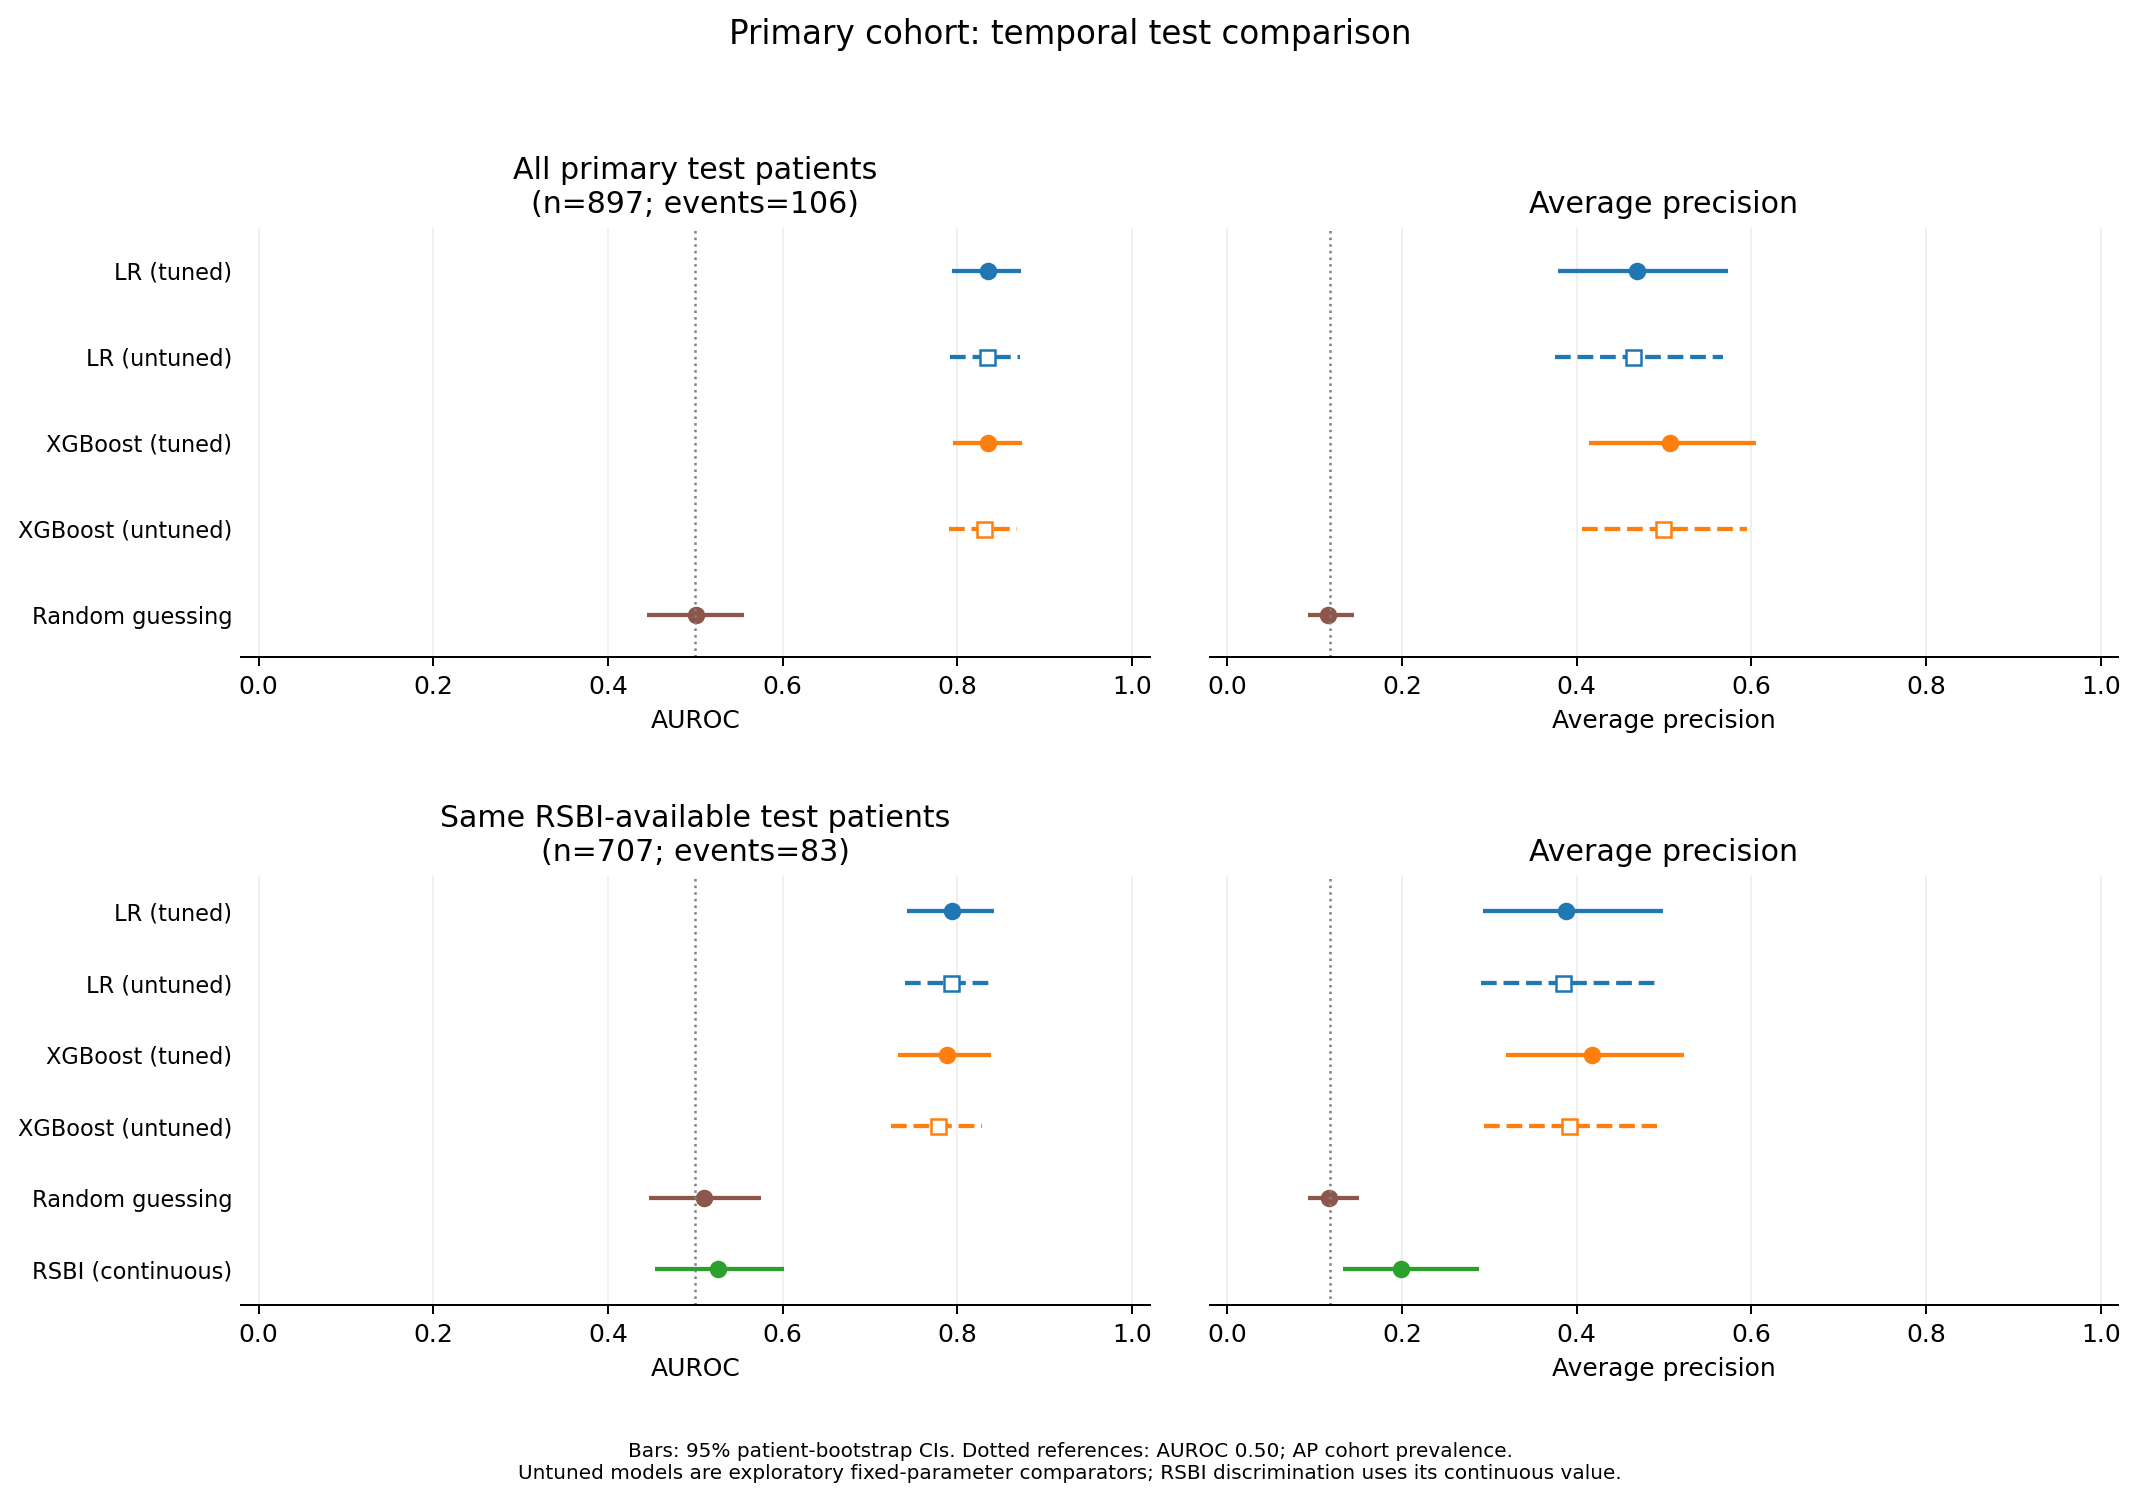

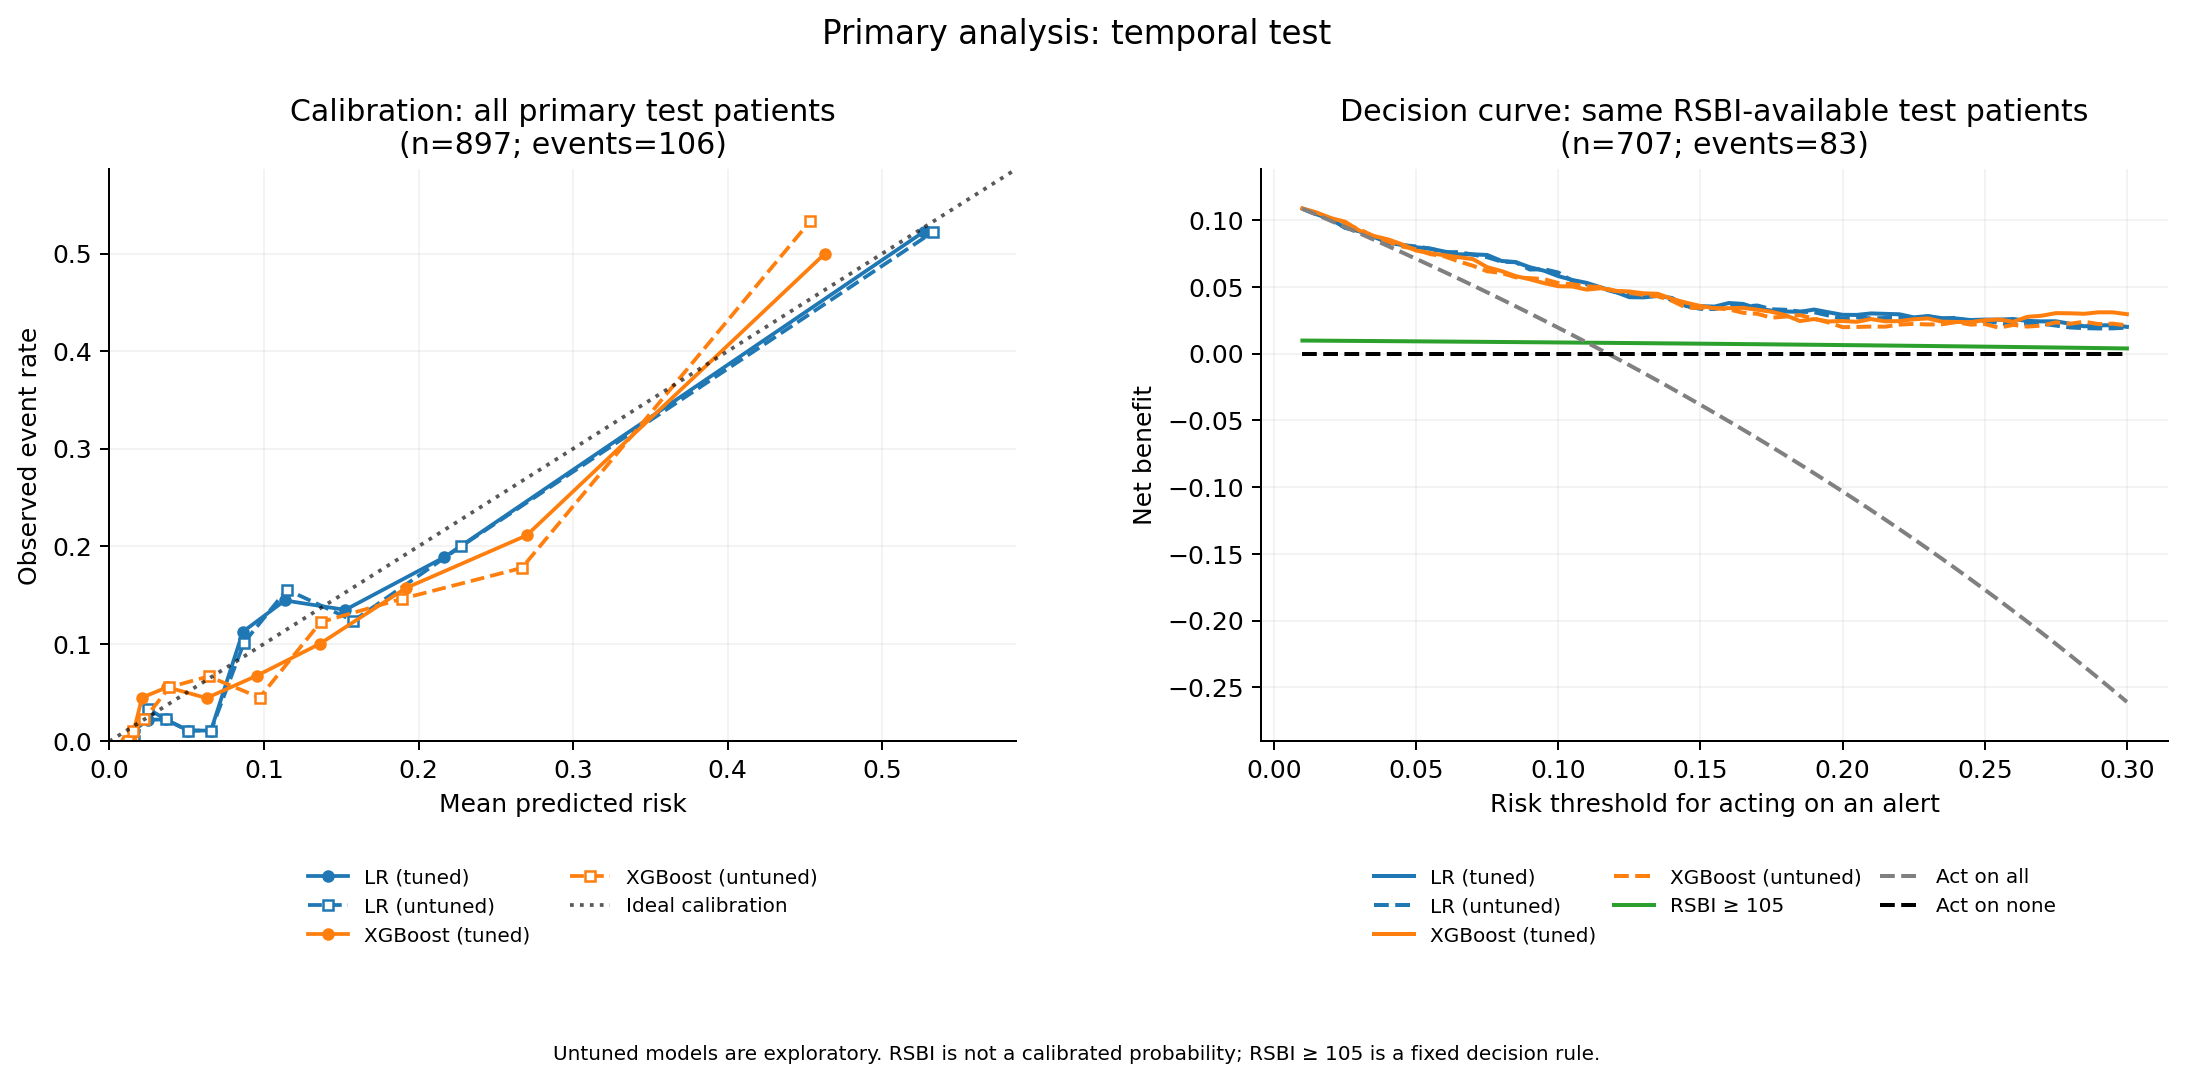

Net benefit at selected risk thresholds (decision-curve patients)


strategy,logistic_regression,logistic_regression_untuned,rsbi_ge_105,treat_all,treat_none,xgboost,xgboost_untuned
threshold,,,,,,,
0.05,0.0796,0.0802,0.0092,0.0709,0.0,0.0771,0.0780
0.10,0.0580,0.0607,0.0083,0.0193,0.0,0.0504,0.0528
0.15,0.0355,0.0335,0.0074,-0.0384,0.0,0.0356,0.0343
0.20,0.0290,0.0262,0.0064,-0.1033,0.0,0.0244,0.0198
0.25,0.0255,0.0245,0.0052,-0.1768,0.0,0.0250,0.0222
0.30,0.0200,0.0194,0.0038,-0.2609,0.0,0.0295,0.0210


Paired model differences A − B: XGBoost vs LR and tuned vs untuned (exploratory additions)


,model_a,model_b,metric,valid_replicates,lower_95,upper_95,n,events,a,b,a_minus_b
0,logistic_regression,logistic_regression_untuned,auroc,1000,-0.001,0.004,897,106,0.835,0.834,0.001
1,logistic_regression,logistic_regression_untuned,average_precision,1000,-0.002,0.012,897,106,0.469,0.465,0.004
2,logistic_regression,logistic_regression_untuned,brier,1000,-0.001,-0.000,897,106,0.081,0.081,-0.001
3,xgboost,logistic_regression,auroc,1000,-0.020,0.020,897,106,0.835,0.835,0.000
4,xgboost,logistic_regression,average_precision,1000,-0.013,0.088,897,106,0.507,0.469,0.038
5,xgboost,logistic_regression,brier,1000,-0.004,0.004,897,106,0.080,0.081,-0.000
6,xgboost,xgboost_untuned,auroc,1000,-0.002,0.012,897,106,0.835,0.831,0.005
7,xgboost,xgboost_untuned,average_precision,1000,-0.009,0.027,897,106,0.507,0.499,0.007
8,xgboost,xgboost_untuned,brier,1000,-0.002,0.000,897,106,0.080,0.081,-0.001


All comparators on identical RSBI-available test patients; continuous RSBI for AUROC/AP, threshold 105 for classification


,model,n,events,auroc,average_precision,sensitivity,specificity,ppv,npv,auroc_lower_95,auroc_upper_95,average_precision_lower_95,average_precision_upper_95
0,logistic_regression,707,83,0.794,0.387,0.892,0.550,0.208,0.974,0.742,0.842,0.292,0.499
1,logistic_regression_untuned,707,83,0.793,0.385,0.892,0.554,0.210,0.975,0.741,0.841,0.291,0.494
2,xgboost,707,83,0.788,0.418,0.843,0.513,0.187,0.961,0.732,0.838,0.319,0.523
3,xgboost_untuned,707,83,0.778,0.391,0.843,0.498,0.183,0.960,0.724,0.828,0.294,0.492
4,random_guess,707,83,0.510,0.116,0.554,0.479,0.124,0.890,0.447,0.575,0.092,0.151
5,rsbi,707,83,0.526,0.199,0.084,0.984,0.412,0.890,0.454,0.601,0.133,0.288


Missingness-filter sensitivity analysis: paired differences A − B with 95% CIs


,comparison,model,patients,events,metric,A,B,A_minus_B,lower_95,upper_95,valid_replicates
0,A full-cohort vs B filtered-cohort training (f...,logistic_regression,897,106,auroc,0.839,0.835,0.003,-0.003,0.008,1000
1,A full-cohort vs B filtered-cohort training (f...,logistic_regression,897,106,average_precision,0.486,0.469,0.017,0.005,0.030,1000
2,A full-cohort vs B filtered-cohort training (f...,logistic_regression,897,106,brier,0.079,0.081,-0.001,-0.003,0.000,1000
3,A full-cohort vs B filtered-cohort training (p...,logistic_regression,196,57,auroc,0.710,0.700,0.010,-0.003,0.024,1000
4,A full-cohort vs B filtered-cohort training (p...,logistic_regression,196,57,average_precision,0.457,0.441,0.017,-0.002,0.039,1000
5,A full-cohort vs B filtered-cohort training (p...,logistic_regression,196,57,brier,0.200,0.206,-0.006,-0.012,0.001,1000
6,A full-cohort vs B filtered-cohort training (f...,logistic_regression_untuned,897,106,auroc,0.836,0.834,0.002,-0.005,0.009,1000
7,A full-cohort vs B filtered-cohort training (f...,logistic_regression_untuned,897,106,average_precision,0.481,0.465,0.016,0.001,0.034,1000
8,A full-cohort vs B filtered-cohort training (f...,logistic_regression_untuned,897,106,brier,0.080,0.081,-0.001,-0.003,0.001,1000
9,A full-cohort vs B filtered-cohort training (p...,logistic_regression_untuned,196,57,auroc,0.711,0.696,0.015,-0.001,0.031,1000


Deaths and reintubations separately against non-events (primary analysis)


,component,model,events,non_events,auroc
0,death_within_48_hours,logistic_regression,58,791,0.885
1,death_within_48_hours,logistic_regression_untuned,58,791,0.883
2,death_within_48_hours,xgboost,58,791,0.912
3,death_within_48_hours,xgboost_untuned,58,791,0.910
4,reintubation_within_48_hours,logistic_regression,51,791,0.766
5,reintubation_within_48_hours,logistic_regression_untuned,51,791,0.766
6,reintubation_within_48_hours,xgboost,51,791,0.741
7,reintubation_within_48_hours,xgboost_untuned,51,791,0.732


In [16]:
final_results = evaluate_suite(runs, RUN_CONFIGS)
TABLE_1 = cohort_table(runs)
TABLE_1.to_csv(SUITE_DIR / "table1_cohort.csv", index=False)
print("Table 1: primary cohort (development and temporal test) and patients removed by the missingness filter")
display(TABLE_1)

summary_columns = ["analysis", "model", "n", "events", "prevalence", "auroc", "auroc_lower_95", "auroc_upper_95",
    "average_precision", "average_precision_lower_95", "average_precision_upper_95", "brier", "scaled_brier",
    "calibration_slope", "observed_expected_ratio", "threshold", "sensitivity", "specificity", "ppv", "npv"]
print("Table 2: temporal test performance (primary and full-cohort six-hour sensitivity; untuned comparisons exploratory)")
display(final_results[summary_columns].round(3))
test_rsbi = rsbi_comparison(pd.read_csv(primary_dir / "FINAL_test_metrics.csv"),
    pd.read_csv(primary_dir / "FINAL_test_patient_bootstrap_CI.csv"))
test_rsbi.to_csv(SUITE_DIR / "FINAL_rsbi_comparison.csv", index=False)
plot_model_comparison(final_results[final_results.analysis.eq("filtered_six_hour")], test_rsbi,
    SUITE_DIR / "FINAL_model_comparison.png", "Primary cohort: temporal test comparison")
display(Image(filename=str(SUITE_DIR / "FINAL_model_comparison.png")))
primary_test = test_predictions(runs["filtered_six_hour"])
display(Image(filename=str(plot_calibration_and_utility(primary_test, CONFIG["decision_curve_max_threshold"],
    SUITE_DIR, "Primary analysis: temporal test"))))
net_benefit_table = pd.read_csv(SUITE_DIR / "FINAL_decision_curve.csv").pivot(
    index="threshold", columns="strategy", values="net_benefit")
print("Net benefit at selected risk thresholds (decision-curve patients)")
display(net_benefit_table.loc[net_benefit_table.index.isin([0.05, 0.1, 0.15, 0.2, 0.25, 0.3])].round(4))

print("Paired model differences A − B: XGBoost vs LR and tuned vs untuned (exploratory additions)")
display(pd.read_csv(primary_dir / "FINAL_paired_model_differences_CI.csv").round(3))
print("All comparators on identical RSBI-available test patients; continuous RSBI for AUROC/AP, threshold 105 for classification")
display(test_rsbi.round(3))

print("Missingness-filter sensitivity analysis: paired differences A − B with 95% CIs")
display(test_sensitivity_analyses(runs).round(3))
print("Deaths and reintubations separately against non-events (primary analysis)")
components = pd.read_csv(primary_dir / "FINAL_outcome_component_auroc.csv")
display(components[components.model.isin(MODEL_NAMES)].reset_index(drop=True).round(3))

Patients/events per comparison: {'(filtered-cohort test patients)': '897/106', '(test patients removed by filter)': '196/57'}


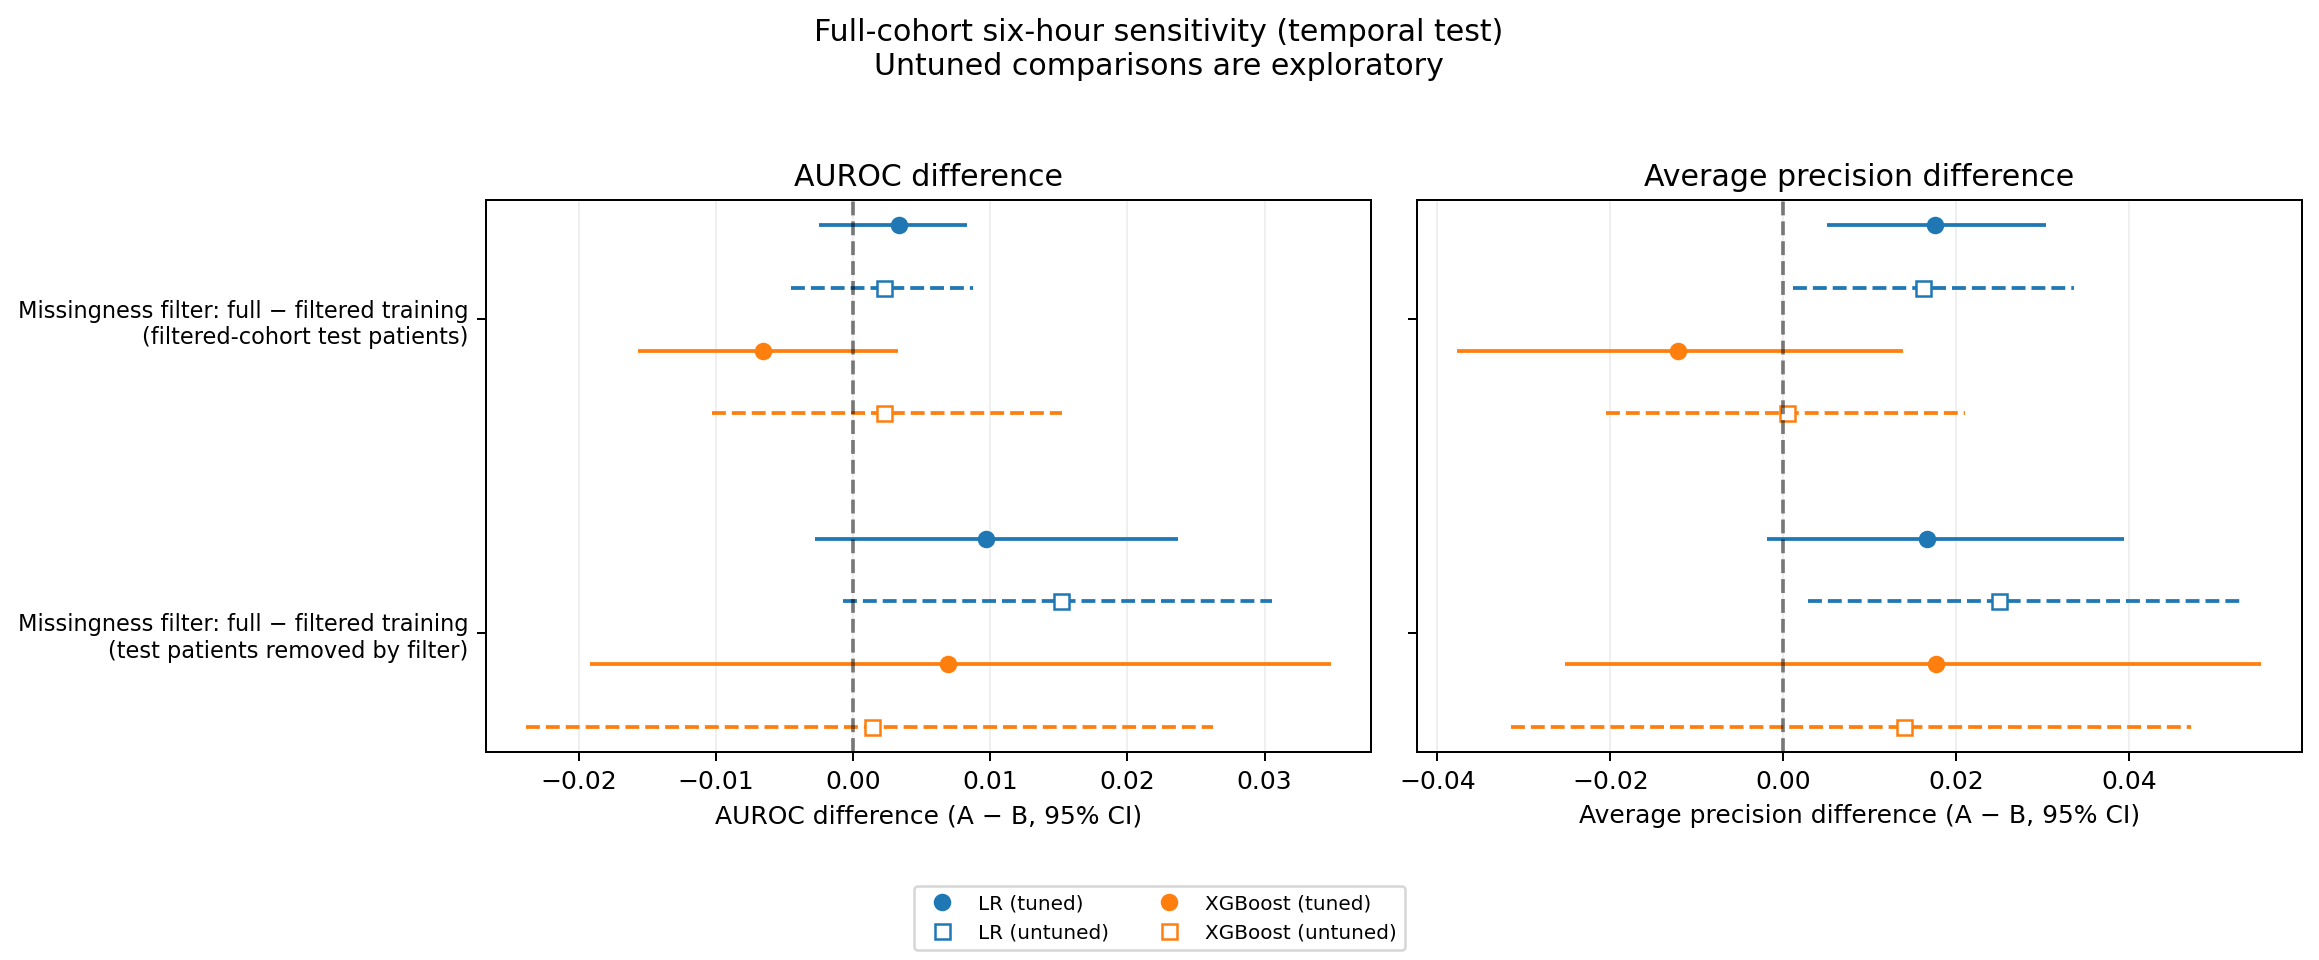

In [17]:
# Missingness-filter sensitivity analysis on the temporal test set: paired differences A − B with 95% bootstrap CIs.
sensitivity = pd.read_csv(SUITE_DIR / "FINAL_sensitivity_analyses.csv")
row_labels = {
    "A full-cohort vs B filtered-cohort training (filtered-cohort patients)":
        "Missingness filter: full − filtered training\n(filtered-cohort test patients)",
    "A full-cohort vs B filtered-cohort training (patients removed by filter)":
        "Missingness filter: full − filtered training\n(test patients removed by filter)",
}
comparisons = [c for c in row_labels if c in set(sensitivity.comparison)]
fig, axes = plt.subplots(1, 2, figsize=(13, 1.6 * len(comparisons) + 2.1), sharey=True)
for ax, metric, title in zip(axes, ["auroc", "average_precision"], ["AUROC difference", "Average precision difference"]):
    for model, offset in zip(MODEL_NAMES, np.linspace(-0.30, 0.30, len(MODEL_NAMES))):
        rows = sensitivity[sensitivity.metric.eq(metric) & sensitivity.model.eq(model)].set_index("comparison").loc[comparisons]
        y = np.arange(len(comparisons)) + offset
        ax.hlines(y, rows.lower_95, rows.upper_95, color=COLOURS[model], linestyles=LINESTYLES[model])
        ax.plot(rows.A_minus_B, y, MARKERS[model], color=COLOURS[model], markerfacecolor="white" if model.endswith("_untuned") else COLOURS[model], label=LABELS[model])
    ax.axvline(0, color="k", linestyle="--", alpha=.5)  # 0 = no difference
    ax.set(xlabel=f"{title} (A − B, 95% CI)", title=title)
    ax.grid(axis="x", alpha=.2)
axes[0].set_yticks(range(len(comparisons)), [row_labels[c] for c in comparisons], fontsize=9)
axes[0].invert_yaxis()
fig.legend(*axes[0].get_legend_handles_labels(), fontsize=8, loc="lower center", ncol=2)
patients = sensitivity.drop_duplicates("comparison").set_index("comparison").loc[comparisons]
print("Patients/events per comparison:", dict(zip([row_labels[c].split("\n")[1] for c in comparisons],
    [f"{int(n)}/{int(e)}" for n, e in zip(patients.patients, patients.events)])))
fig.suptitle("Full-cohort six-hour sensitivity (temporal test)\nUntuned comparisons are exploratory")
fig.tight_layout(rect=(0, .10, 1, .96))
fig.savefig(SUITE_DIR / "FINAL_sensitivity_analyses.png", dpi=180, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(SUITE_DIR / "FINAL_sensitivity_analyses.png")))

## Generative AI declaration

We declare the use of claude [claude.ai] and ChatGPT[openai.com] to check the code, formate and structure it. We also used them to check for grammar, sentence structure and overall flow of the code and the report. 